# Module 5: Multi-Table Relational Merging, Time-Series Growth & Revenue Anomaly Detection
**Project:** Multi-Source Retail Analytics & Anomaly Detection Pipeline  
**Author:** Piyush Kumar Singh  
**Stack:** Python 3.12+, Pandas, NumPy, Matplotlib, Statsmodels (`seasonal_decompose`)  
**Input:** `orders_cleaned.csv`, `customers_cleaned.csv`, `products_cleaned.csv`  
**Output:** Integrated Master Fact Table (`final_ecommerce_analysis.csv`), Temporal Resampling, Statistical Anomaly Detection Logs

---

### Executive Summary & Business Objective
This module implements the end-to-end analytical consolidation of the multi-source retail pipeline:
1. **Relational Data Integration (Star Schema):** Merging the transactional order fact table with customer and product dimension tables via foreign keys (`customer_id`, `product_id`) to generate a unified master enterprise dataset (`final_df`).
2. **Multi-Dimensional Cross-Tabulation & Pivot Tables:** Engineering categorical slice-and-dice matrices (City $\times$ Product Category, Payment Rail volumes).
3. **Temporal Resampling & Revenue Velocity:** Re-indexing transaction timestamps to construct Daily (`D`), Monthly (`MS`), Quarterly (`QS`), and Annual (`YS`) time series; evaluating Month-over-Month (MoM) and Quarter-over-Quarter (QoQ) revenue trajectories.
4. **Trend Smoothing & Seasonal Decomposition:** Modeling 3-month and 6-month rolling moving averages, day-of-week sales indices, and decomposing revenue into Trend, Seasonality, and Noise components via `statsmodels.tsa.seasonal.seasonal_decompose`.
5. **Statistical Anomaly Detection Suite:**
   - **Interquartile Range (IQR) Filter:** Flagging observations breaching $[Q_1 - 1.5 \times IQR, Q_3 + 1.5 \times IQR]$.
   - **Z-Score Filter:** Isolating severe statistical anomalies departing by more than 3 standard deviations from the population mean ($|Z| > 3$).
   - **Dynamic Rolling Upper Envelope:** Identifying sudden demand surges breaching moving 30-day thresholds.
   - **Visualizing Outlier Spikes:** Rendering comprehensive timeline plots highlighting flagged anomalies.

## 1. Environment Setup & Library Initialization
Import core analytical packages: `pandas`, `numpy`, `matplotlib.pyplot`, and `statsmodels`.

In [1]:
import numpy as np
import pandas as pd

In [2]:
orders=pd.read_csv('orders_cleaned.csv')
customers=pd.read_csv('customers_cleaned.csv')
products=pd.read_csv('products_cleaned.csv')
pd.options.display.float_format = '{:,.2f}'.format

In [3]:
print(orders.shape)
print(customers.shape)
print(products.shape)

print('_'*100)

print(orders.columns)
print('_'*100)
print(customers.columns)
print('_'*100)
print(products.columns)

(49652, 18)
(6060, 8)
(350, 6)
____________________________________________________________________________________________________
Index(['order_id', 'order_date', 'customer_id', 'product_id', 'quantity',
       'unit_price', 'discount', 'total_amount', 'payment_method',
       'order_status', 'sales_channel', 'shipping_city', 'customer_age',
       'returned', 'rating', 'coupon_code', 'device', 'marketing_source'],
      dtype='str')
____________________________________________________________________________________________________
Index(['customer_id', 'customer_name', 'email', 'city', 'country',
       'signup_date', 'age', 'customer_segment'],
      dtype='str')
____________________________________________________________________________________________________
Index(['product_id', 'product_name', 'category', 'brand', 'list_price',
       'supplier_id'],
      dtype='str')


In [4]:
# print('duplicate customer id',customers['customer_id'].duplicated().sum())
# print('duplicate product id ', products['product_id'].duplicated().sum())

print(
    "Duplicate customer IDs:",
    customers['customer_id'].duplicated().sum()
)

print(
    "Duplicate product IDs:",
    products['product_id'].duplicated().sum()
)

Duplicate customer IDs: 60
Duplicate product IDs: 0


In [5]:
print(
    "missing customer IDs:",
    customers['customer_id'].isnull().sum()
)

print(
    "missing product IDs:",
    products['product_id'].isnull().sum()
)

missing customer IDs: 0
missing product IDs: 0


## 2. Customer Dimension Deduplication & Referential Pre-Checks
Audit the customer dimension for primary key duplicates before merging to prevent row multiplication during relational joins.

In [6]:
customers[customers['customer_id']=='CUST11871']

,customer_id,customer_name,email,city,country,signup_date,age,customer_segment
1871,CUST11871,Rohan Singh,user1871@example.com,Delhi,India,2020-12-29,33.00,Premium
6002,CUST11871,Rohan Singh,user1871@example.com,Delhi,India,2020-12-29,33.00,Premium


In [7]:
customers[customers['customer_id'].duplicated()]

,customer_id,customer_name,email,city,country,signup_date,age,customer_segment
6000,CUST13802,Rahul Singh,user3802@example.com,Jaipur,India,2022-09-07,22.00,New
6001,CUST13297,Vikram Mehta,user3297@example.com,Lucknow,India,2020-10-25,23.00,Regular
6002,CUST11871,Rohan Singh,user1871@example.com,Delhi,India,2020-12-29,33.00,Premium
6003,CUST13122,Rohan Das,user3122@example.com,Hyderabad,India,2025-06-23,54.00,Regular
6004,CUST14352,Ananya Gupta,user4352@example.com,Kolkata,UK,2024-06-12,66.00,Premium
6005,CUST13282,Rohan Mehta,user3282@example.com,Lucknow,India,2022-12-22,35.00,VIP
6006,CUST12374,Isha Kumar,user2374@example.com,Bengaluru,India,2025-10-05,61.00,Regular
6007,CUST15811,Rohan Sharma,user5811@example.com,Pune,UAE,2023-11-22,54.00,VIP
6008,CUST13663,Vikram Kumar,user3663@example.com,Lucknow,India,2019-04-16,20.00,Premium
6009,CUST14085,Amit Verma,user4085@example.com,Pune,India,2024-01-21,59.00,Regular


In [8]:
customers=customers.drop_duplicates(subset='customer_id',keep='first')

In [9]:
customers.duplicated().sum()

np.int64(0)

## 3. Relational Table Joins: Evaluating Inner, Left, Right & Outer Merges
Evaluate relational join behaviors across `orders` and `customers`:
- **Inner Merge:** Retains only matching keys.
- **Left Merge:** Preserves all transactional order records.
- **Outer Merge:** Captures unactivated customer accounts.
Then construct the master dataset `final_df` by joining `orders_customers` with the `products` dimension on `product_id`.

In [10]:
inner_merge=pd.merge(
    orders,
    customers,
    on='customer_id',
    how='inner'
)
inner_merge.tail()

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,...,coupon_code,device,marketing_source,customer_name,email,city,country,signup_date,age,customer_segment
49647,ORD0049998,2023-12-26,CUST10127,PROD0125,4.00,"25,098.01",0.00,"100,392.03",CREDIT CARD,Delivered,...,WELCOME10,Mac,Social Media,Aarav Sharma,user127@example.com,Chennai,India,2024-05-23,63.00,New
49648,ORD0049999,2022-06-05,CUST15950,PROD0228,4.00,"30,239.82",0.25,"90,719.45",UPI,Delivered,...,NEWUSER,Windows,Social Media,Rohan Mehta,user5950@example.com,Bengaluru,India,2025-10-30,46.00,VIP
49649,ORD0050000,2023-12-30,CUST12687,PROD0312,4.00,"45,491.51",0.15,"154,671.15",WALLET,Delivered,...,FESTIVE20,Mac,Organic,Vikram Singh,user2687@example.com,Kolkata,India,2025-07-08,21.00,Regular
49650,ORD0026509,2025-09-28,CUST11655,PROD0287,4.00,"5,516.51",0.00,"22,066.06",CREDIT CARD,Delivered,...,NONE,Android,Organic,Aarav Reddy,user1655@example.com,Bengaluru,India,2022-05-25,27.00,Premium
49651,ORD0003676,2022-08-31,CUST13704,PROD0073,2.00,"12,840.23",0.05,"24,396.44",DEBIT CARD,Delivered,...,NONE,iOS,Organic,Vikram Singh,user3704@example.com,Lucknow,India,2019-12-02,52.00,New


In [11]:
left_merge=pd.merge(
    orders,
    customers,
    on='customer_id',
    how='left'
)
left_merge.tail()

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,...,coupon_code,device,marketing_source,customer_name,email,city,country,signup_date,age,customer_segment
49647,ORD0049998,2023-12-26,CUST10127,PROD0125,4.00,"25,098.01",0.00,"100,392.03",CREDIT CARD,Delivered,...,WELCOME10,Mac,Social Media,Aarav Sharma,user127@example.com,Chennai,India,2024-05-23,63.00,New
49648,ORD0049999,2022-06-05,CUST15950,PROD0228,4.00,"30,239.82",0.25,"90,719.45",UPI,Delivered,...,NEWUSER,Windows,Social Media,Rohan Mehta,user5950@example.com,Bengaluru,India,2025-10-30,46.00,VIP
49649,ORD0050000,2023-12-30,CUST12687,PROD0312,4.00,"45,491.51",0.15,"154,671.15",WALLET,Delivered,...,FESTIVE20,Mac,Organic,Vikram Singh,user2687@example.com,Kolkata,India,2025-07-08,21.00,Regular
49650,ORD0026509,2025-09-28,CUST11655,PROD0287,4.00,"5,516.51",0.00,"22,066.06",CREDIT CARD,Delivered,...,NONE,Android,Organic,Aarav Reddy,user1655@example.com,Bengaluru,India,2022-05-25,27.00,Premium
49651,ORD0003676,2022-08-31,CUST13704,PROD0073,2.00,"12,840.23",0.05,"24,396.44",DEBIT CARD,Delivered,...,NONE,iOS,Organic,Vikram Singh,user3704@example.com,Lucknow,India,2019-12-02,52.00,New


In [12]:
right_merge=pd.merge(
    orders,
    customers,
    on='customer_id',
    how='right'
)
right_merge.head()

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,...,coupon_code,device,marketing_source,customer_name,email,city,country,signup_date,age,customer_segment
0,ORD0006033,2023-06-11,CUST10000,PROD0324,2.00,"7,462.94",0.05,"14,179.58",DEBIT CARD,Delivered,...,NONE,iOS,Referral,Priya Sharma,user0@example.com,Ranchi,India,2023-12-23,70.00,Regular
1,ORD0007240,2022-01-17,CUST10000,PROD0095,5.00,"38,539.21",0.10,"173,426.43",WALLET,Pending,...,NEWUSER,Windows,Search Ads,Priya Sharma,user0@example.com,Ranchi,India,2023-12-23,70.00,Regular
2,ORD0009736,2024-10-04,CUST10000,PROD0181,4.00,"43,769.43",0.10,"157,569.96",NET BANKING,Delivered,...,WELCOME10,Android,Referral,Priya Sharma,user0@example.com,Ranchi,India,2023-12-23,70.00,Regular
3,ORD0010391,2026-01-03,CUST10000,PROD0192,3.00,"15,177.76",0.15,"38,703.29",UPI,Delivered,...,WELCOME10,iOS,Email,Priya Sharma,user0@example.com,Ranchi,India,2023-12-23,70.00,Regular
4,ORD0012964,2023-08-24,CUST10000,PROD0054,5.00,"19,937.59",0.15,"84,734.76",CASH,Shipped,...,NONE,Other,Email,Priya Sharma,user0@example.com,Ranchi,India,2023-12-23,70.00,Regular


In [13]:
outer_merge=pd.merge(
    orders,
    customers,
    on='customer_id',
    how='outer'
)
outer_merge.head()

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,...,coupon_code,device,marketing_source,customer_name,email,city,country,signup_date,age,customer_segment
0,ORD0006033,2023-06-11,CUST10000,PROD0324,2.00,"7,462.94",0.05,"14,179.58",DEBIT CARD,Delivered,...,NONE,iOS,Referral,Priya Sharma,user0@example.com,Ranchi,India,2023-12-23,70.00,Regular
1,ORD0007240,2022-01-17,CUST10000,PROD0095,5.00,"38,539.21",0.10,"173,426.43",WALLET,Pending,...,NEWUSER,Windows,Search Ads,Priya Sharma,user0@example.com,Ranchi,India,2023-12-23,70.00,Regular
2,ORD0009736,2024-10-04,CUST10000,PROD0181,4.00,"43,769.43",0.10,"157,569.96",NET BANKING,Delivered,...,WELCOME10,Android,Referral,Priya Sharma,user0@example.com,Ranchi,India,2023-12-23,70.00,Regular
3,ORD0010391,2026-01-03,CUST10000,PROD0192,3.00,"15,177.76",0.15,"38,703.29",UPI,Delivered,...,WELCOME10,iOS,Email,Priya Sharma,user0@example.com,Ranchi,India,2023-12-23,70.00,Regular
4,ORD0012964,2023-08-24,CUST10000,PROD0054,5.00,"19,937.59",0.15,"84,734.76",CASH,Shipped,...,NONE,Other,Email,Priya Sharma,user0@example.com,Ranchi,India,2023-12-23,70.00,Regular


In [14]:
print("Inner:", inner_merge.shape)
print("Left:", left_merge.shape)
print("Right:", right_merge.shape)
print("Outer:", outer_merge.shape)

Inner: (49652, 25)
Left: (49652, 25)
Right: (49654, 25)
Outer: (49654, 25)


In [15]:
orders_customers=pd.merge(
    orders,
    customers,
    on='customer_id',
    how='left',
    validate='many_to_one'
)
orders_customers.head()

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,...,coupon_code,device,marketing_source,customer_name,email,city,country,signup_date,age,customer_segment
0,ORD0000001,2025-12-11,CUST12577,PROD0232,2.00,"38,741.08",0.05,"71,452.04",WALLET,Delivered,...,NONE,Android,Referral,Amit Singh,user2577@example.com,Hyderabad,India,2022-06-01,50.00,New
1,ORD0000002,2026-06-04,CUST15421,PROD0317,3.00,"26,541.85",0.10,"71,662.99",NET BANKING,Cancelled,...,NONE,Android,Search Ads,Rahul Reddy,user5421@example.com,Lucknow,India,2023-03-16,28.00,Regular
2,ORD0000003,2024-12-25,CUST14130,PROD0124,4.00,"11,645.74",0.20,"37,266.37",WALLET,Shipped,...,WELCOME10,Android,Organic,Vikram Reddy,user4130@example.com,Ranchi,India,2019-05-09,34.00,Regular
3,ORD0000004,2023-02-04,CUST14117,PROD0012,4.00,"45,006.44",0.00,"180,025.77",CREDIT CARD,Delivered,...,NONE,Windows,Email,Amit Kumar,user4117@example.com,Bengaluru,India,2025-05-28,25.00,Regular
4,ORD0000005,2023-01-16,CUST13087,PROD0274,2.00,"43,124.43",0.25,"86,248.86",CREDIT CARD,Delivered,...,NONE,Other,Social Media,Rahul Reddy,user3087@example.com,Bengaluru,India,2024-04-16,33.00,Premium


In [16]:
final_df=pd.merge(
    orders_customers,
    products,
    on='product_id',
    how='left',
    validate='many_to_one',
    suffixes=('_order','_product')
)
final_df.head()

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,...,city,country,signup_date,age,customer_segment,product_name,category,brand,list_price,supplier_id
0,ORD0000001,2025-12-11,CUST12577,PROD0232,2.00,"38,741.08",0.05,"71,452.04",WALLET,Delivered,...,Hyderabad,India,2022-06-01,50.00,New,Classic Bag 232,Clothing,DailyChoice,"40,611.40",SUP134
1,ORD0000002,2026-06-04,CUST15421,PROD0317,3.00,"26,541.85",0.10,"71,662.99",NET BANKING,Cancelled,...,Lucknow,India,2023-03-16,28.00,Regular,Pro Shoes 317,Beauty,FitWay,"28,873.22",SUP102
2,ORD0000003,2024-12-25,CUST14130,PROD0124,4.00,"11,645.74",0.20,"37,266.37",WALLET,Shipped,...,Ranchi,India,2019-05-09,34.00,Regular,Pro Phone 124,Beauty,TechSphere,"12,026.09",SUP137
3,ORD0000004,2023-02-04,CUST14117,PROD0012,4.00,"45,006.44",0.00,"180,025.77",CREDIT CARD,Delivered,...,Bengaluru,India,2025-05-28,25.00,Regular,Classic Bag 12,Clothing,HomeNest,"40,365.06",SUP109
4,ORD0000005,2023-01-16,CUST13087,PROD0274,2.00,"43,124.43",0.25,"86,248.86",CREDIT CARD,Delivered,...,Bengaluru,India,2024-04-16,33.00,Premium,Pro Watch 274,Clothing,DailyChoice,"46,748.53",SUP122


In [17]:
final_df.columns

Index(['order_id', 'order_date', 'customer_id', 'product_id', 'quantity',
       'unit_price', 'discount', 'total_amount', 'payment_method',
       'order_status', 'sales_channel', 'shipping_city', 'customer_age',
       'returned', 'rating', 'coupon_code', 'device', 'marketing_source',
       'customer_name', 'email', 'city', 'country', 'signup_date', 'age',
       'customer_segment', 'product_name', 'category', 'brand', 'list_price',
       'supplier_id'],
      dtype='str')

## 4. Master Dataset Exploratory Diagnostics & Category Rollups
Inspect descriptive statistics of `final_df` and compute revenue distribution across product categories, customer cities, and top accounts.

In [18]:
final_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 49652 entries, 0 to 49651
Data columns (total 30 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          49652 non-null  str    
 1   order_date        49652 non-null  str    
 2   customer_id       49652 non-null  str    
 3   product_id        49652 non-null  str    
 4   quantity          49652 non-null  float64
 5   unit_price        49652 non-null  float64
 6   discount          49652 non-null  float64
 7   total_amount      49652 non-null  float64
 8   payment_method    49652 non-null  str    
 9   order_status      49652 non-null  str    
 10  sales_channel     49652 non-null  str    
 11  shipping_city     49652 non-null  str    
 12  customer_age      49652 non-null  float64
 13  returned          49652 non-null  int64  
 14  rating            49652 non-null  float64
 15  coupon_code       49652 non-null  str    
 16  device            49652 non-null  str    
 17  mark

In [19]:
final_df.describe()

,quantity,unit_price,discount,total_amount,customer_age,returned,rating,age,list_price
count,"49,652.00","49,652.00","49,652.00","49,652.00","49,652.00","49,652.00","49,652.00","49,652.00","46,871.00"
mean,2.99,"24,060.40",0.11,"65,329.95",46.20,0.07,3.92,46.08,"25,445.66"
std,1.41,"13,873.74",0.09,"52,497.06",16.11,0.26,1.04,16.10,"14,219.60"
min,1.00,720.28,0.00,595.27,5.00,0.00,0.00,8.00,959.12
25%,2.00,"11,831.91",0.00,"23,198.19",33.00,0.00,4.00,33.00,"12,815.21"
50%,3.00,"24,099.61",0.10,"50,297.96",46.00,0.00,4.00,46.00,"25,835.38"
75%,4.00,"35,105.07",0.15,"96,533.10",60.00,0.00,5.00,60.00,"38,378.12"
max,5.00,"57,395.90",0.30,"286,424.11",74.00,1.00,10.00,74.00,"49,999.13"


In [20]:
category_revenue=final_df.groupby('category')['total_amount'].sum().sort_values(ascending=False)
category_revenue

category
Books            589,150,297.92
Grocery          552,192,378.94
Clothing         496,501,881.43
Beauty           461,813,053.83
Home & Kitchen   410,784,930.19
Sports           403,587,368.01
Electronics      329,732,852.17
Name: total_amount, dtype: float64

In [21]:
revenue_by_customer_city=final_df.groupby('city')['total_amount'].sum().sort_values(ascending=False)
revenue_by_customer_city

city
Bengaluru   426,812,734.04
Kolkata     324,626,936.26
Chennai     323,700,819.98
Hyderabad   322,242,677.97
Lucknow     320,611,966.19
Delhi       317,026,556.56
Ranchi      312,628,705.79
Mumbai      305,790,739.61
Pune        296,765,539.57
Jaipur      293,556,086.54
Name: total_amount, dtype: float64

In [22]:
top_10_customers=final_df.groupby(['customer_id', 'customer_name'])['total_amount'].sum().sort_values(ascending=False).head(10)
top_10_customers

customer_id  customer_name
CUST15762    Priya Kumar     2,178,412.36
CUST11251    Neha Singh      1,781,891.91
CUST14663    Ananya Sharma   1,681,732.01
CUST15067    Neha Kumar      1,514,754.03
CUST11021    Amit Singh      1,472,681.78
CUST10190    Ananya Gupta    1,429,308.54
CUST10282    Amit Reddy      1,411,754.00
CUST15020    Rohan Mehta     1,382,976.88
CUST13670    Sneha Kumar     1,365,423.95
CUST10609    Priya Singh     1,355,715.95
Name: total_amount, dtype: float64

In [23]:
customers_indexd=customers.set_index('customer_id')
orders_index=orders.set_index('customer_id')

In [24]:
customers_indexd

,customer_name,email,city,country,signup_date,age,customer_segment
customer_id,,,,,,,
CUST10000,Priya Sharma,user0@example.com,Ranchi,India,2023-12-23,70.00,Regular
CUST10001,Amit Gupta,user1@example.com,Chennai,India,2024-12-24,47.00,New
CUST10002,Ananya Kumar,user2@example.com,Pune,India,2019-12-25,53.00,Regular
CUST10003,Priya Singh,user3@example.com,Hyderabad,India,2020-09-07,38.00,Premium
CUST10004,Isha Reddy,user4@example.com,Hyderabad,India,2019-04-04,68.00,Regular
...,...,...,...,...,...,...,...
CUST15995,Sneha Verma,user5995@example.com,Delhi,UK,2021-10-09,24.00,Premium
CUST15996,Rahul Verma,user5996@example.com,Jaipur,India,2021-09-03,70.00,VIP
CUST15997,Vikram Sharma,user5997@example.com,Lucknow,India,2024-08-10,35.00,Premium


## 5. Alternative Relational Joins & Data Harmonization
Evaluate DataFrame `.join()` methodologies using index-based merging, suffix handling, and data type reconciliations.

In [25]:
orders_index

,order_id,order_date,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source
customer_id,,,,,,,,,,,,,,,,,
CUST12577,ORD0000001,2025-12-11,PROD0232,2.00,"38,741.08",0.05,"71,452.04",WALLET,Delivered,Website,Mumbai,50.00,0,5.00,NONE,Android,Referral
CUST15421,ORD0000002,2026-06-04,PROD0317,3.00,"26,541.85",0.10,"71,662.99",NET BANKING,Cancelled,In-store,Chennai,28.00,0,5.00,NONE,Android,Search Ads
CUST14130,ORD0000003,2024-12-25,PROD0124,4.00,"11,645.74",0.20,"37,266.37",WALLET,Shipped,Marketplace,Hyderabad,34.00,0,4.00,WELCOME10,Android,Organic
CUST14117,ORD0000004,2023-02-04,PROD0012,4.00,"45,006.44",0.00,"180,025.77",CREDIT CARD,Delivered,Marketplace,Ranchi,25.00,0,5.00,NONE,Windows,Email
CUST13087,ORD0000005,2023-01-16,PROD0274,2.00,"43,124.43",0.25,"86,248.86",CREDIT CARD,Delivered,In-store,Chennai,33.00,0,2.00,NONE,Other,Social Media
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CUST10127,ORD0049998,2023-12-26,PROD0125,4.00,"25,098.01",0.00,"100,392.03",CREDIT CARD,Delivered,Marketplace,Mumbai,63.00,0,5.00,WELCOME10,Mac,Social Media
CUST15950,ORD0049999,2022-06-05,PROD0228,4.00,"30,239.82",0.25,"90,719.45",UPI,Delivered,Website,Jaipur,42.00,0,4.00,NEWUSER,Windows,Social Media
CUST12687,ORD0050000,2023-12-30,PROD0312,4.00,"45,491.51",0.15,"154,671.15",WALLET,Delivered,Marketplace,Delhi,21.00,0,4.00,FESTIVE20,Mac,Organic


In [26]:
join_df=orders_index.join(
    customers_indexd,
    on='customer_id',
    how='left',
    lsuffix='_left',
    rsuffix='_right'
)
join_df.columns

Index(['order_id', 'order_date', 'product_id', 'quantity', 'unit_price',
       'discount', 'total_amount', 'payment_method', 'order_status',
       'sales_channel', 'shipping_city', 'customer_age', 'returned', 'rating',
       'coupon_code', 'device', 'marketing_source', 'customer_name', 'email',
       'city', 'country', 'signup_date', 'age', 'customer_segment'],
      dtype='str')

In [27]:
join_d=orders_index.join(
    customers_indexd,
    on='customer_id',
    how='left'
)
join_d

,order_id,order_date,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,...,coupon_code,device,marketing_source,customer_name,email,city,country,signup_date,age,customer_segment
customer_id,,,,,,,,,,,,,,,,,,,,,
CUST12577,ORD0000001,2025-12-11,PROD0232,2.00,"38,741.08",0.05,"71,452.04",WALLET,Delivered,Website,...,NONE,Android,Referral,Amit Singh,user2577@example.com,Hyderabad,India,2022-06-01,50.00,New
CUST15421,ORD0000002,2026-06-04,PROD0317,3.00,"26,541.85",0.10,"71,662.99",NET BANKING,Cancelled,In-store,...,NONE,Android,Search Ads,Rahul Reddy,user5421@example.com,Lucknow,India,2023-03-16,28.00,Regular
CUST14130,ORD0000003,2024-12-25,PROD0124,4.00,"11,645.74",0.20,"37,266.37",WALLET,Shipped,Marketplace,...,WELCOME10,Android,Organic,Vikram Reddy,user4130@example.com,Ranchi,India,2019-05-09,34.00,Regular
CUST14117,ORD0000004,2023-02-04,PROD0012,4.00,"45,006.44",0.00,"180,025.77",CREDIT CARD,Delivered,Marketplace,...,NONE,Windows,Email,Amit Kumar,user4117@example.com,Bengaluru,India,2025-05-28,25.00,Regular
CUST13087,ORD0000005,2023-01-16,PROD0274,2.00,"43,124.43",0.25,"86,248.86",CREDIT CARD,Delivered,In-store,...,NONE,Other,Social Media,Rahul Reddy,user3087@example.com,Bengaluru,India,2024-04-16,33.00,Premium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CUST10127,ORD0049998,2023-12-26,PROD0125,4.00,"25,098.01",0.00,"100,392.03",CREDIT CARD,Delivered,Marketplace,...,WELCOME10,Mac,Social Media,Aarav Sharma,user127@example.com,Chennai,India,2024-05-23,63.00,New
CUST15950,ORD0049999,2022-06-05,PROD0228,4.00,"30,239.82",0.25,"90,719.45",UPI,Delivered,Website,...,NEWUSER,Windows,Social Media,Rohan Mehta,user5950@example.com,Bengaluru,India,2025-10-30,46.00,VIP
CUST12687,ORD0050000,2023-12-30,PROD0312,4.00,"45,491.51",0.15,"154,671.15",WALLET,Delivered,Marketplace,...,FESTIVE20,Mac,Organic,Vikram Singh,user2687@example.com,Kolkata,India,2025-07-08,21.00,Regular


In [28]:
# Example 1 — Basic join() and the four how types

left = pd.DataFrame({
    "sales": [100, 200, 300]
}, index=["Delhi", "Mumbai", "Pune"])

right = pd.DataFrame({
    "returns": [10, 20, 30]
}, index=["Delhi", "Mumbai", "Chennai"])

print("LEFT join (default):")
print(left.join(right))

print("\nINNER join:")
print(left.join(right, how="inner"))

print("\nRIGHT join:")
print(left.join(right, how="right"))

print("\nOUTER join:")
print(left.join(right, how="outer"))

# LEFT join (default): sales returns Delhi 100 10.0 Mumbai 200 20.0 Pune 300 NaN INNER join: sales returns Delhi 100 10 Mumbai 200 20 RIGHT join: sales returns Delhi 100.0 10 Mumbai 200.0 20 Chennai NaN 30 OUTER join: sales returns Chennai NaN 30.0 Delhi 100.0 10.0 Mumbai 200.0 20.0 Pune 300.0 NaN

LEFT join (default):
        sales  returns
Delhi     100    10.00
Mumbai    200    20.00
Pune      300      NaN

INNER join:
        sales  returns
Delhi     100       10
Mumbai    200       20

RIGHT join:
         sales  returns
Delhi   100.00       10
Mumbai  200.00       20
Chennai    NaN       30

OUTER join:
         sales  returns
Chennai    NaN    30.00
Delhi   100.00    10.00
Mumbai  200.00    20.00
Pune    300.00      NaN


In [29]:
# Example 2 — Suffixes and join on a column

# Duplicate column name -> need suffixes
left = pd.DataFrame({"value": [10, 20]}, index=["x", "y"])
right = pd.DataFrame({"value": [100, 200]}, index=["x", "y"])

print("lsuffix / rsuffix:")
print(left.join(right, lsuffix="_L", rsuffix="_R"))

# Join a left column against the right index
orders = pd.DataFrame({
    "customer_id": [101, 102, 103],
    "amount": [250, 400, 150]
})

customer = pd.DataFrame({
    "name": ["Ravi", "Anita", "Sam"]
}, index=[101, 102, 103])

print("\njoin with on='customer_id':")
print(orders.join(customer, on="customer_id"))

# Left join keeps unmatched left rows
customer_partial = customer.iloc[:2]
print("\nleft join with partial right (missing 103):")
print(orders.join(customer_partial, on="customer_id", how="left"))


# lsuffix / rsuffix: value_L value_R x 10 100 y 20 200 join with on='customer_id': customer_id amount name 0 101 250 Ravi 1 102 400 Anita 2 103 150 Sam left join with partial right (missing 103): customer_id amount name 0 101 250 Ravi 1 102 400 Anita 2 103 150 NaN

lsuffix / rsuffix:
   value_L  value_R
x       10      100
y       20      200

join with on='customer_id':
   customer_id  amount   name
0          101     250   Ravi
1          102     400  Anita
2          103     150    Sam

left join with partial right (missing 103):
   customer_id  amount   name
0          101     250   Ravi
1          102     400  Anita
2          103     150    NaN


In [30]:
pd.set_option('display.max.columns',40)

array([<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
       <Axes: >, <Axes: >, <Axes: >], dtype=object)

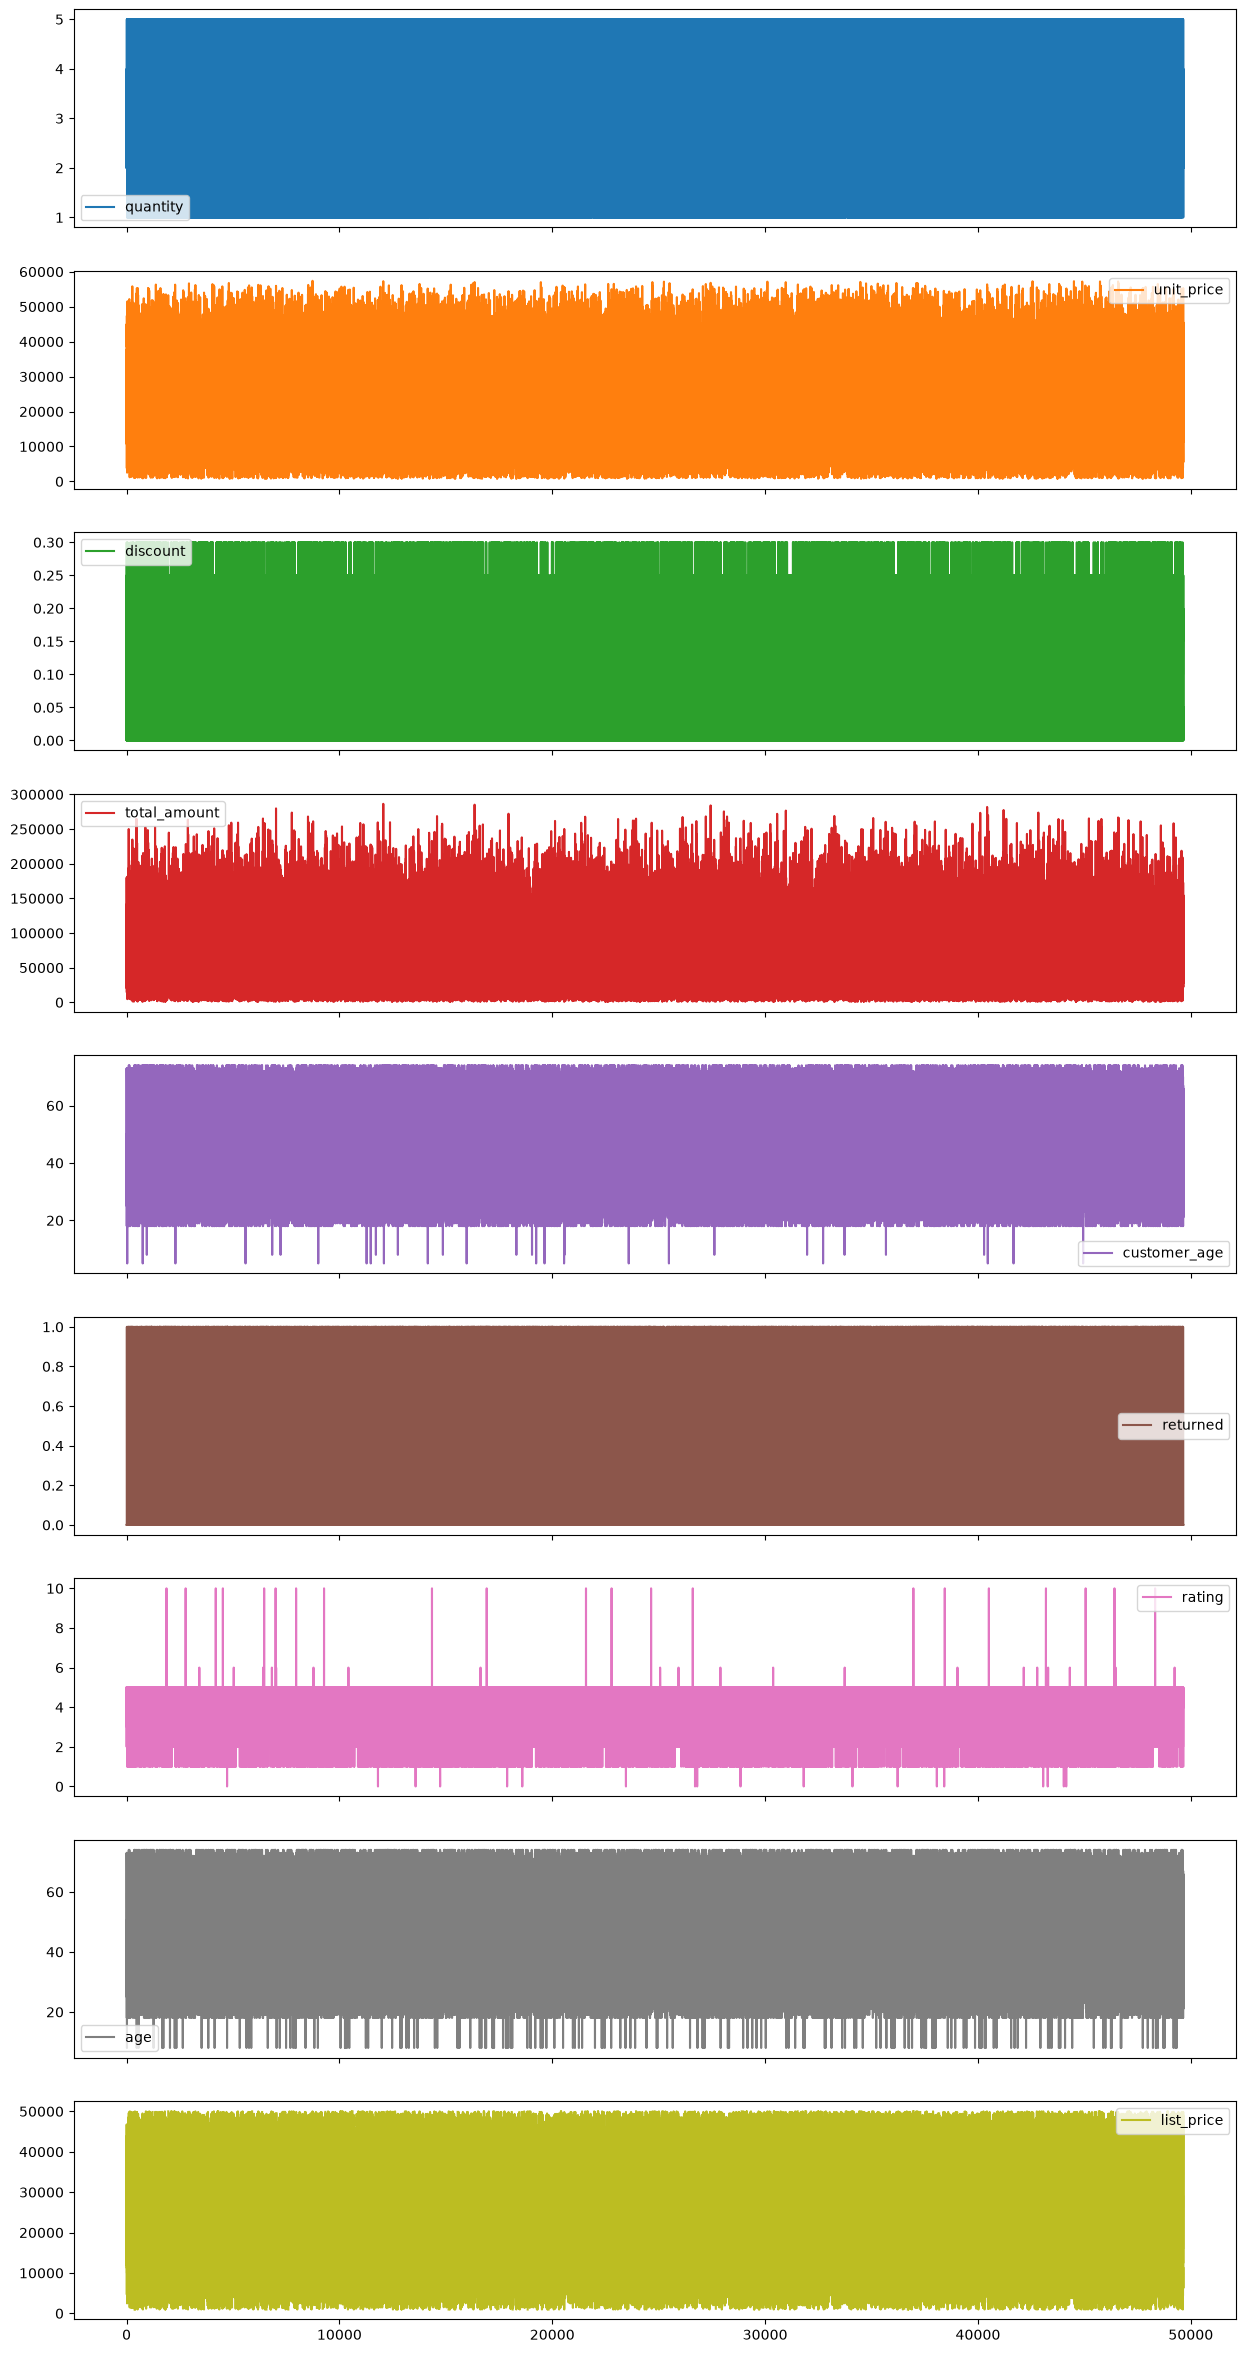

In [31]:
final_df.plot(subplots=True, figsize=(15,30))

In [32]:
final_df['rating']=final_df['rating'].replace(6,3)

In [33]:
final_df['rating'].unique()

array([ 5.,  4.,  2.,  3.,  1., 10.,  0.])

In [34]:
# final_df.plot(kind='bar',figzise=(15,30))

<Axes: xlabel='customer_age', ylabel='total_amount'>

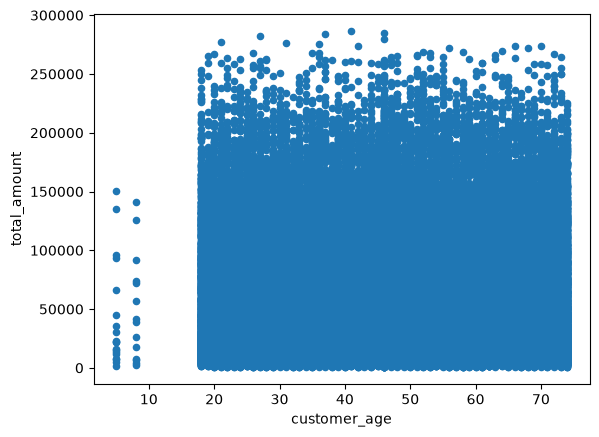

In [35]:
final_df.plot.scatter(x='customer_age',y='total_amount')

In [36]:
jan_sales = pd.DataFrame({
    'month': ['January', 'January'],
    'revenue': [10000, 15000]
})

feb_sales = pd.DataFrame({
    'month': ['February', 'February'],
    'revenue': [20000, 25000]
})

In [37]:
all_sales = pd.concat(
    [jan_sales, feb_sales],
    axis=0,
    ignore_index=True
)

all_sales

,month,revenue
0,January,10000
1,January,15000
2,February,20000
3,February,25000


In [38]:
horizontal = pd.concat(
    [jan_sales, feb_sales],
    axis=1
)

horizontal

,month,revenue,month,revenue
0,January,10000,February,20000
1,January,15000,February,25000


In [39]:
first_half=final_df[final_df['order_date']< '2025-01-01']
second_half=final_df[final_df['order_date']>='2025-01-01']

combined_sales=pd.concat(
    [first_half,second_half],ignore_index=True
)
combined_sales

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source,customer_name,email,city,country,signup_date,age,customer_segment,product_name,category,brand,list_price,supplier_id
0,ORD0000003,2024-12-25,CUST14130,PROD0124,4.00,"11,645.74",0.20,"37,266.37",WALLET,Shipped,Marketplace,Hyderabad,34.00,0,4.00,WELCOME10,Android,Organic,Vikram Reddy,user4130@example.com,Ranchi,India,2019-05-09,34.00,Regular,Pro Phone 124,Beauty,TechSphere,"12,026.09",SUP137
1,ORD0000004,2023-02-04,CUST14117,PROD0012,4.00,"45,006.44",0.00,"180,025.77",CREDIT CARD,Delivered,Marketplace,Ranchi,25.00,0,5.00,NONE,Windows,Email,Amit Kumar,user4117@example.com,Bengaluru,India,2025-05-28,25.00,Regular,Classic Bag 12,Clothing,HomeNest,"40,365.06",SUP109
2,ORD0000005,2023-01-16,CUST13087,PROD0274,2.00,"43,124.43",0.25,"86,248.86",CREDIT CARD,Delivered,In-store,Chennai,33.00,0,2.00,NONE,Other,Social Media,Rahul Reddy,user3087@example.com,Bengaluru,India,2024-04-16,33.00,Premium,Pro Watch 274,Clothing,DailyChoice,"46,748.53",SUP122
3,ORD0000009,2024-05-07,CUST13091,PROD0318,3.00,"34,681.52",0.15,"88,437.87",UPI,Delivered,Website,Chennai,63.00,0,4.00,WELCOME10,iOS,Organic,Isha Sharma,user3091@example.com,Mumbai,India,2024-10-08,63.00,Regular,Premium Headphones 318,Grocery,DailyChoice,"36,071.60",SUP116
4,ORD0000010,2022-09-22,CUST14344,PROD0142,5.00,"22,439.67",0.05,"106,588.44",CREDIT CARD,Delivered,In-store,Jaipur,66.00,0,4.00,NONE,Android,Organic,Ananya Mehta,user4344@example.com,Mumbai,India,2025-04-22,66.00,Regular,Basic Shoes 142,Grocery,FitWay,"28,304.97",SUP139
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49647,ORD0049973,2025-03-18,CUST14691,PROD0126,1.00,"5,613.11",0.15,"4,771.14",NET BANKING,Pending,Marketplace,Kolkata,40.00,0,5.00,NONE,Other,Referral,Rohan Singh,user4691@example.com,Ranchi,India,2022-07-15,40.00,VIP,Classic T-Shirt 126,Beauty,TechSphere,"7,260.76",SUP110
49648,ORD0049980,2026-07-24,CUST15412,PROD0059,2.00,"16,461.04",0.15,"27,983.77",WALLET,Delivered,Website,Mumbai,63.00,0,2.00,NONE,Android,Referral,Rohan Mehta,user5412@example.com,Kolkata,India,2019-09-27,63.00,Regular,Basic Shoes 59,Sports,TechSphere,"20,457.40",SUP139
49649,ORD0049983,2025-03-21,CUST12385,PROD0176,4.00,"35,192.54",0.10,"126,693.15",DEBIT CARD,Shipped,Marketplace,Ranchi,28.00,0,5.00,NONE,Windows,Social Media,Rahul Kumar,user2385@example.com,Jaipur,India,2021-02-01,28.00,New,Smart Shoes 176,Clothing,Nova,"32,693.70",SUP118
49650,ORD0049984,2025-05-14,CUST12807,PROD0230,5.00,"3,891.82",0.20,"19,459.10",NET BANKING,Delivered,Mobile App,Chennai,56.00,0,5.00,NONE,Mac,Email,Ananya Singh,user2807@example.com,Mumbai,India,2023-01-01,56.00,Premium,Ultra Bag 230,Beauty,HomeNest,"4,374.97",SUP120


In [40]:
first_half

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source,customer_name,email,city,country,signup_date,age,customer_segment,product_name,category,brand,list_price,supplier_id
2,ORD0000003,2024-12-25,CUST14130,PROD0124,4.00,"11,645.74",0.20,"37,266.37",WALLET,Shipped,Marketplace,Hyderabad,34.00,0,4.00,WELCOME10,Android,Organic,Vikram Reddy,user4130@example.com,Ranchi,India,2019-05-09,34.00,Regular,Pro Phone 124,Beauty,TechSphere,"12,026.09",SUP137
3,ORD0000004,2023-02-04,CUST14117,PROD0012,4.00,"45,006.44",0.00,"180,025.77",CREDIT CARD,Delivered,Marketplace,Ranchi,25.00,0,5.00,NONE,Windows,Email,Amit Kumar,user4117@example.com,Bengaluru,India,2025-05-28,25.00,Regular,Classic Bag 12,Clothing,HomeNest,"40,365.06",SUP109
4,ORD0000005,2023-01-16,CUST13087,PROD0274,2.00,"43,124.43",0.25,"86,248.86",CREDIT CARD,Delivered,In-store,Chennai,33.00,0,2.00,NONE,Other,Social Media,Rahul Reddy,user3087@example.com,Bengaluru,India,2024-04-16,33.00,Premium,Pro Watch 274,Clothing,DailyChoice,"46,748.53",SUP122
8,ORD0000009,2024-05-07,CUST13091,PROD0318,3.00,"34,681.52",0.15,"88,437.87",UPI,Delivered,Website,Chennai,63.00,0,4.00,WELCOME10,iOS,Organic,Isha Sharma,user3091@example.com,Mumbai,India,2024-10-08,63.00,Regular,Premium Headphones 318,Grocery,DailyChoice,"36,071.60",SUP116
9,ORD0000010,2022-09-22,CUST14344,PROD0142,5.00,"22,439.67",0.05,"106,588.44",CREDIT CARD,Delivered,In-store,Jaipur,66.00,0,4.00,NONE,Android,Organic,Ananya Mehta,user4344@example.com,Mumbai,India,2025-04-22,66.00,Regular,Basic Shoes 142,Grocery,FitWay,"28,304.97",SUP139
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49646,ORD0049997,2022-01-07,CUST11899,PROD0008,1.00,"27,115.26",0.00,"27,115.26",DEBIT CARD,Delivered,Marketplace,Lucknow,66.00,0,4.00,WELCOME10,Android,Organic,Isha Das,user1899@example.com,Mumbai,India,2022-10-04,66.00,Regular,Ultra Phone 8,Books,Nova,"34,805.24",SUP120
49647,ORD0049998,2023-12-26,CUST10127,PROD0125,4.00,"25,098.01",0.00,"100,392.03",CREDIT CARD,Delivered,Marketplace,Mumbai,63.00,0,5.00,WELCOME10,Mac,Social Media,Aarav Sharma,user127@example.com,Chennai,India,2024-05-23,63.00,New,Pro Bag 125,Sports,Nova,"30,056.71",SUP116
49648,ORD0049999,2022-06-05,CUST15950,PROD0228,4.00,"30,239.82",0.25,"90,719.45",UPI,Delivered,Website,Jaipur,42.00,0,4.00,NEWUSER,Windows,Social Media,Rohan Mehta,user5950@example.com,Bengaluru,India,2025-10-30,46.00,VIP,Premium T-Shirt 228,Sports,UrbanLeaf,"36,985.49",SUP125
49649,ORD0050000,2023-12-30,CUST12687,PROD0312,4.00,"45,491.51",0.15,"154,671.15",WALLET,Delivered,Marketplace,Delhi,21.00,0,4.00,FESTIVE20,Mac,Organic,Vikram Singh,user2687@example.com,Kolkata,India,2025-07-08,21.00,Regular,Classic Headphones 312,Clothing,FitWay,"48,538.91",SUP133


## 6. Multi-Dimensional Cross-Tabulation & Pivot Modeling
Construct multi-dimensional pivot tables to analyze revenue and order volume across intersecting dimensions:
- City $\times$ Product Category
- City $\times$ Payment Method
- Stacked and unstacked hierarchical representations

In [41]:
pivot=pd.pivot_table(
    final_df,
    index='city',
    columns='category',
    values='total_amount',
    aggfunc='sum',
    fill_value=0
)
pivot

category,Beauty,Books,Clothing,Electronics,Grocery,Home & Kitchen,Sports
city,,,,,,,
Bengaluru,"60,275,491.25","79,472,662.02","63,960,972.30","44,214,123.17","73,834,232.22","53,261,028.94","51,794,224.13"
Chennai,"50,582,872.88","55,322,867.64","50,376,567.09","31,542,910.92","55,633,183.57","38,157,337.48","42,085,080.39"
Delhi,"44,096,717.20","56,732,210.71","44,075,558.75","32,971,473.02","55,088,684.49","43,300,349.06","40,761,563.33"
Hyderabad,"49,082,092.35","57,190,037.24","50,369,376.12","32,957,354.75","55,957,404.56","38,551,949.87","38,134,463.07"
Jaipur,"43,123,612.53","48,397,977.64","47,322,076.37","27,910,498.86","48,462,871.33","41,755,706.24","36,583,343.57"
Kolkata,"43,433,822.82","60,733,521.55","49,616,957.51","33,712,479.28","55,688,071.51","40,429,739.96","41,012,343.63"
Lucknow,"42,855,932.01","60,417,291.66","46,957,496.08","32,363,757.23","54,921,019.42","40,928,547.27","42,167,922.53"
Mumbai,"42,502,629.11","55,869,550.82","46,123,202.20","31,392,506.51","52,380,204.48","38,633,376.80","38,889,269.70"
Pune,"44,935,530.55","53,684,795.41","49,059,478.94","29,925,235.30","48,167,584.38","37,015,406.18","33,977,508.81"


In [42]:
pd.pivot_table(
    final_df,
    index='city',
    values='total_amount',
    aggfunc='sum'
)

,total_amount
city,
Bengaluru,"426,812,734.04"
Chennai,"323,700,819.98"
Delhi,"317,026,556.56"
Hyderabad,"322,242,677.97"
Jaipur,"293,556,086.54"
Kolkata,"324,626,936.26"
Lucknow,"320,611,966.19"
Mumbai,"305,790,739.61"
Pune,"296,765,539.57"


In [43]:
rev_cit=final_df.groupby('city')['total_amount'].sum()
rev_cit

city
Bengaluru   426,812,734.04
Chennai     323,700,819.98
Delhi       317,026,556.56
Hyderabad   322,242,677.97
Jaipur      293,556,086.54
Kolkata     324,626,936.26
Lucknow     320,611,966.19
Mumbai      305,790,739.61
Pune        296,765,539.57
Ranchi      312,628,705.79
Name: total_amount, dtype: float64

In [44]:
pd.pivot_table(
    final_df,
    index='city',
    values='total_amount',
    aggfunc='mean'
)

,total_amount
city,
Bengaluru,"64,639.21"
Chennai,"65,619.46"
Delhi,"66,644.22"
Hyderabad,"65,723.57"
Jaipur,"64,974.79"
Kolkata,"65,094.63"
Lucknow,"64,058.33"
Mumbai,"64,635.54"
Pune,"65,627.05"


In [45]:
final_df['city'].describe()

count         49652
unique           10
top       Bengaluru
freq           6603
Name: city, dtype: object

In [46]:
final_df.describe()

,quantity,unit_price,discount,total_amount,customer_age,returned,rating,age,list_price
count,"49,652.00","49,652.00","49,652.00","49,652.00","49,652.00","49,652.00","49,652.00","49,652.00","46,871.00"
mean,2.99,"24,060.40",0.11,"65,329.95",46.20,0.07,3.92,46.08,"25,445.66"
std,1.41,"13,873.74",0.09,"52,497.06",16.11,0.26,1.03,16.10,"14,219.60"
min,1.00,720.28,0.00,595.27,5.00,0.00,0.00,8.00,959.12
25%,2.00,"11,831.91",0.00,"23,198.19",33.00,0.00,4.00,33.00,"12,815.21"
50%,3.00,"24,099.61",0.10,"50,297.96",46.00,0.00,4.00,46.00,"25,835.38"
75%,4.00,"35,105.07",0.15,"96,533.10",60.00,0.00,5.00,60.00,"38,378.12"
max,5.00,"57,395.90",0.30,"286,424.11",74.00,1.00,10.00,74.00,"49,999.13"


In [47]:
pd.pivot_table(
    final_df,
    index='city',
    values='order_id',
    aggfunc='nunique'

)

,order_id
city,
Bengaluru,6602
Chennai,4933
Delhi,4757
Hyderabad,4903
Jaipur,4518
Kolkata,4987
Lucknow,5004
Mumbai,4731
Pune,4522


In [48]:
pd.pivot_table(
    final_df,
    index='city',
    values='total_amount',
    aggfunc=['sum','mean','median']
)

,sum,mean,median
,total_amount,total_amount,total_amount
city,,,
Bengaluru,"426,812,734.04","64,639.21","49,630.83"
Chennai,"323,700,819.98","65,619.46","51,001.98"
Delhi,"317,026,556.56","66,644.22","51,885.88"
Hyderabad,"322,242,677.97","65,723.57","51,832.23"
Jaipur,"293,556,086.54","64,974.79","49,633.23"
Kolkata,"324,626,936.26","65,094.63","49,360.75"
Lucknow,"320,611,966.19","64,058.33","48,990.56"
Mumbai,"305,790,739.61","64,635.54","49,328.03"


In [49]:
sales_pivot=pd.pivot_table(
    final_df,
    index='city',
    columns='payment_method',
    values='total_amount',
    aggfunc='sum',
    fill_value=0
)
sales_pivot

payment_method,CASH,CREDIT CARD,DEBIT CARD,NET BANKING,NETBANKING,UPI,WALLET
city,,,,,,,
Bengaluru,"76,661,330.82","69,230,383.86","77,635,497.49","66,553,081.42","3,227,266.23","67,819,404.34","65,685,769.87"
Chennai,"57,755,055.57","54,478,464.96","56,778,086.28","47,481,484.56","3,116,307.26","51,658,154.71","52,433,266.63"
Delhi,"50,565,126.97","50,741,275.16","55,685,328.43","47,498,900.26","3,691,525.34","54,674,860.28","54,169,540.13"
Hyderabad,"50,056,085.09","53,097,420.34","55,598,868.44","51,482,476.03","3,442,167.16","56,920,140.67","51,645,520.24"
Jaipur,"51,517,967.15","46,042,564.56","53,855,896.05","42,214,564.26","2,825,152.29","48,990,758.23","48,109,183.99"
Kolkata,"54,785,162.38","50,657,616.92","63,792,161.99","49,496,150.36","3,384,205.74","49,008,295.68","53,503,343.19"
Lucknow,"52,813,834.33","53,451,619.17","57,704,862.02","50,525,579.44","2,891,506.42","49,908,110.05","53,316,454.76"
Mumbai,"49,266,085.84","51,127,970.04","54,262,923.08","50,804,866.76","2,687,717.56","49,004,173.98","48,637,002.35"
Pune,"47,816,945.17","52,287,359.46","54,381,577.85","41,909,107.30","3,239,084.30","48,092,703.85","49,038,761.63"


In [50]:
stacked_df=sales_pivot.stack()
stacked_df

city       payment_method
Bengaluru  CASH             76,661,330.82
           CREDIT CARD      69,230,383.86
           DEBIT CARD       77,635,497.49
           NET BANKING      66,553,081.42
           NETBANKING        3,227,266.23
                                 ...     
Ranchi     DEBIT CARD       57,639,118.48
           NET BANKING      47,760,424.48
           NETBANKING        3,336,389.37
           UPI              54,058,342.41
           WALLET           47,113,196.78
Length: 70, dtype: float64

In [51]:
unstacked_df=stacked_df.unstack()
unstacked_df

payment_method,CASH,CREDIT CARD,DEBIT CARD,NET BANKING,NETBANKING,UPI,WALLET
city,,,,,,,
Bengaluru,"76,661,330.82","69,230,383.86","77,635,497.49","66,553,081.42","3,227,266.23","67,819,404.34","65,685,769.87"
Chennai,"57,755,055.57","54,478,464.96","56,778,086.28","47,481,484.56","3,116,307.26","51,658,154.71","52,433,266.63"
Delhi,"50,565,126.97","50,741,275.16","55,685,328.43","47,498,900.26","3,691,525.34","54,674,860.28","54,169,540.13"
Hyderabad,"50,056,085.09","53,097,420.34","55,598,868.44","51,482,476.03","3,442,167.16","56,920,140.67","51,645,520.24"
Jaipur,"51,517,967.15","46,042,564.56","53,855,896.05","42,214,564.26","2,825,152.29","48,990,758.23","48,109,183.99"
Kolkata,"54,785,162.38","50,657,616.92","63,792,161.99","49,496,150.36","3,384,205.74","49,008,295.68","53,503,343.19"
Lucknow,"52,813,834.33","53,451,619.17","57,704,862.02","50,525,579.44","2,891,506.42","49,908,110.05","53,316,454.76"
Mumbai,"49,266,085.84","51,127,970.04","54,262,923.08","50,804,866.76","2,687,717.56","49,004,173.98","48,637,002.35"
Pune,"47,816,945.17","52,287,359.46","54,381,577.85","41,909,107.30","3,239,084.30","48,092,703.85","49,038,761.63"


In [52]:
final_df.to_csv(
    'final_ecommerce_analysis.csv',
    index=False
)

## 7. Master Enterprise Dataset Export (CSV, Excel & JSON)
Persist the consolidated analytical master table to disk in multiple enterprise-standard formats (`.csv`, `.xlsx`, `.json`) for downstream BI ingestion and data engineering pipelines.

In [53]:
# final_df.to_excel(
#     'final_ecommerce_analysis.xlsx',
#     index=False
# )

In [54]:
final_df.to_json(
    'final_ecommerce_analysis.json',
    orient='records',
    indent=4
)

In [55]:
from sqlalchemy import create_engine,text
from sqlalchemy.engine import URL


In [56]:
connection_url=URL.create(
    drivername='mysql+pymysql',
    username='root',
    password='',
    host='127.0.0.1',
    port=int(3306),
    database='final_ecommerce_analysis'
)

engine=create_engine(connection_url)

In [57]:
# final_df.to_sql(name='final_ecommerce_analysis',con=engine, index=False, if_exists='replace')

In [58]:
# query='select * from final_ecommerce_analysis'
# ch=pd.read_sql(query,con=engine)
# ch

In [59]:
prod_me = orders_customers.merge(
    products,
    on='product_id',
    how='inner'
)
prod_me.head()

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source,customer_name,email,city,country,signup_date,age,customer_segment,product_name,category,brand,list_price,supplier_id
0,ORD0000001,2025-12-11,CUST12577,PROD0232,2.00,"38,741.08",0.05,"71,452.04",WALLET,Delivered,Website,Mumbai,50.00,0,5.00,NONE,Android,Referral,Amit Singh,user2577@example.com,Hyderabad,India,2022-06-01,50.00,New,Classic Bag 232,Clothing,DailyChoice,"40,611.40",SUP134
1,ORD0000002,2026-06-04,CUST15421,PROD0317,3.00,"26,541.85",0.10,"71,662.99",NET BANKING,Cancelled,In-store,Chennai,28.00,0,5.00,NONE,Android,Search Ads,Rahul Reddy,user5421@example.com,Lucknow,India,2023-03-16,28.00,Regular,Pro Shoes 317,Beauty,FitWay,"28,873.22",SUP102
2,ORD0000003,2024-12-25,CUST14130,PROD0124,4.00,"11,645.74",0.20,"37,266.37",WALLET,Shipped,Marketplace,Hyderabad,34.00,0,4.00,WELCOME10,Android,Organic,Vikram Reddy,user4130@example.com,Ranchi,India,2019-05-09,34.00,Regular,Pro Phone 124,Beauty,TechSphere,"12,026.09",SUP137
3,ORD0000004,2023-02-04,CUST14117,PROD0012,4.00,"45,006.44",0.00,"180,025.77",CREDIT CARD,Delivered,Marketplace,Ranchi,25.00,0,5.00,NONE,Windows,Email,Amit Kumar,user4117@example.com,Bengaluru,India,2025-05-28,25.00,Regular,Classic Bag 12,Clothing,HomeNest,"40,365.06",SUP109
4,ORD0000005,2023-01-16,CUST13087,PROD0274,2.00,"43,124.43",0.25,"86,248.86",CREDIT CARD,Delivered,In-store,Chennai,33.00,0,2.00,NONE,Other,Social Media,Rahul Reddy,user3087@example.com,Bengaluru,India,2024-04-16,33.00,Premium,Pro Watch 274,Clothing,DailyChoice,"46,748.53",SUP122


In [60]:
revenue_by_product_category=final_df.groupby('category')['total_amount'].sum()
revenue_by_product_category

category
Beauty           461,813,053.83
Books            589,150,297.92
Clothing         496,501,881.43
Electronics      329,732,852.17
Grocery          552,192,378.94
Home & Kitchen   410,784,930.19
Sports           403,587,368.01
Name: total_amount, dtype: float64

In [61]:
top_10_customer_by_spending=final_df.groupby('customer_id')['total_amount'].sum().sort_values(ascending=False).head(10)
top_10_customer_by_spending

customer_id
CUST15762   2,178,412.36
CUST11251   1,781,891.91
CUST14663   1,681,732.01
CUST15067   1,514,754.03
CUST11021   1,472,681.78
CUST10190   1,429,308.54
CUST10282   1,411,754.00
CUST15020   1,382,976.88
CUST13670   1,365,423.95
CUST10609   1,355,715.95
Name: total_amount, dtype: float64

In [62]:
inner_join=orders_index.join(customers_indexd,on='customer_id' , how='left',lsuffix='_left', rsuffix='_right')
inner_join

,order_id,order_date,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source,customer_name,email,city,country,signup_date,age,customer_segment
customer_id,,,,,,,,,,,,,,,,,,,,,,,,
CUST12577,ORD0000001,2025-12-11,PROD0232,2.00,"38,741.08",0.05,"71,452.04",WALLET,Delivered,Website,Mumbai,50.00,0,5.00,NONE,Android,Referral,Amit Singh,user2577@example.com,Hyderabad,India,2022-06-01,50.00,New
CUST15421,ORD0000002,2026-06-04,PROD0317,3.00,"26,541.85",0.10,"71,662.99",NET BANKING,Cancelled,In-store,Chennai,28.00,0,5.00,NONE,Android,Search Ads,Rahul Reddy,user5421@example.com,Lucknow,India,2023-03-16,28.00,Regular
CUST14130,ORD0000003,2024-12-25,PROD0124,4.00,"11,645.74",0.20,"37,266.37",WALLET,Shipped,Marketplace,Hyderabad,34.00,0,4.00,WELCOME10,Android,Organic,Vikram Reddy,user4130@example.com,Ranchi,India,2019-05-09,34.00,Regular
CUST14117,ORD0000004,2023-02-04,PROD0012,4.00,"45,006.44",0.00,"180,025.77",CREDIT CARD,Delivered,Marketplace,Ranchi,25.00,0,5.00,NONE,Windows,Email,Amit Kumar,user4117@example.com,Bengaluru,India,2025-05-28,25.00,Regular
CUST13087,ORD0000005,2023-01-16,PROD0274,2.00,"43,124.43",0.25,"86,248.86",CREDIT CARD,Delivered,In-store,Chennai,33.00,0,2.00,NONE,Other,Social Media,Rahul Reddy,user3087@example.com,Bengaluru,India,2024-04-16,33.00,Premium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CUST10127,ORD0049998,2023-12-26,PROD0125,4.00,"25,098.01",0.00,"100,392.03",CREDIT CARD,Delivered,Marketplace,Mumbai,63.00,0,5.00,WELCOME10,Mac,Social Media,Aarav Sharma,user127@example.com,Chennai,India,2024-05-23,63.00,New
CUST15950,ORD0049999,2022-06-05,PROD0228,4.00,"30,239.82",0.25,"90,719.45",UPI,Delivered,Website,Jaipur,42.00,0,4.00,NEWUSER,Windows,Social Media,Rohan Mehta,user5950@example.com,Bengaluru,India,2025-10-30,46.00,VIP
CUST12687,ORD0050000,2023-12-30,PROD0312,4.00,"45,491.51",0.15,"154,671.15",WALLET,Delivered,Marketplace,Delhi,21.00,0,4.00,FESTIVE20,Mac,Organic,Vikram Singh,user2687@example.com,Kolkata,India,2025-07-08,21.00,Regular


In [63]:
outer_join=orders_index.join(customers_indexd,on='customer_id',how='outer',lsuffix='_left',rsuffix='_right')

outer_join

,customer_id,order_id,order_date,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source,customer_name,email,city,country,signup_date,age,customer_segment
CUST10000,CUST10000,ORD0006033,2023-06-11,PROD0324,2.00,"7,462.94",0.05,"14,179.58",DEBIT CARD,Delivered,Mobile App,Bangalore,70.00,0.00,4.00,NONE,iOS,Referral,Priya Sharma,user0@example.com,Ranchi,India,2023-12-23,70.00,Regular
CUST10000,CUST10000,ORD0007240,2022-01-17,PROD0095,5.00,"38,539.21",0.10,"173,426.43",WALLET,Pending,Website,Chennai,70.00,0.00,4.00,NEWUSER,Windows,Search Ads,Priya Sharma,user0@example.com,Ranchi,India,2023-12-23,70.00,Regular
CUST10000,CUST10000,ORD0009736,2024-10-04,PROD0181,4.00,"43,769.43",0.10,"157,569.96",NET BANKING,Delivered,Marketplace,Kolkata,70.00,0.00,5.00,WELCOME10,Android,Referral,Priya Sharma,user0@example.com,Ranchi,India,2023-12-23,70.00,Regular
CUST10000,CUST10000,ORD0010391,2026-01-03,PROD0192,3.00,"15,177.76",0.15,"38,703.29",UPI,Delivered,Marketplace,Jaipur,70.00,0.00,5.00,WELCOME10,iOS,Email,Priya Sharma,user0@example.com,Ranchi,India,2023-12-23,70.00,Regular
CUST10000,CUST10000,ORD0012964,2023-08-24,PROD0054,5.00,"19,937.59",0.15,"84,734.76",CASH,Shipped,Website,Jaipur,70.00,0.00,4.00,NONE,Other,Email,Priya Sharma,user0@example.com,Ranchi,India,2023-12-23,70.00,Regular
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CUST15999,CUST15999,ORD0023067,2022-10-28,PROD0028,5.00,"8,127.22",0.10,"36,572.48",CASH,Delivered,In-store,Delhi,66.00,0.00,4.00,FESTIVE20,Android,Search Ads,Aarav Singh,user5999@example.com,Ranchi,India,2023-03-23,66.00,Regular
CUST15999,CUST15999,ORD0026405,2023-06-28,PROD0098,3.00,"27,390.85",0.10,"82,172.55",CREDIT CARD,Shipped,Mobile App,Kolkata,66.00,0.00,4.00,WELCOME10,iOS,Search Ads,Aarav Singh,user5999@example.com,Ranchi,India,2023-03-23,66.00,Regular
CUST15999,CUST15999,ORD0033270,2024-05-26,PROD0309,3.00,"35,119.57",0.15,"89,554.89",NET BANKING,Cancelled,In-store,Lucknow,66.00,0.00,4.00,NONE,Other,Organic,Aarav Singh,user5999@example.com,Ranchi,India,2023-03-23,66.00,Regular
CUST15999,CUST15999,ORD0046182,2024-02-20,PROD0085,1.00,"21,331.51",0.25,"15,998.63",UPI,Delivered,Website,Bangalore,66.00,0.00,5.00,WELCOME10,Other,Organic,Aarav Singh,user5999@example.com,Ranchi,India,2023-03-23,66.00,Regular


In [64]:
conc = pd.concat([orders, customer], axis=0, ignore_index=True)
conc

,customer_id,amount,name
0,101.00,250.00,NaN
1,102.00,400.00,NaN
2,103.00,150.00,NaN
3,NaN,NaN,Ravi
4,NaN,NaN,Anita
5,NaN,NaN,Sam


In [65]:
customer

,name
101,Ravi
102,Anita
103,Sam


In [66]:
city_by_revenue=pd.pivot_table(
    final_df,
    index='city',
    columns='payment_method',
    values='total_amount',
    aggfunc='sum',
    fill_value=0
)
city_by_revenue

payment_method,CASH,CREDIT CARD,DEBIT CARD,NET BANKING,NETBANKING,UPI,WALLET
city,,,,,,,
Bengaluru,"76,661,330.82","69,230,383.86","77,635,497.49","66,553,081.42","3,227,266.23","67,819,404.34","65,685,769.87"
Chennai,"57,755,055.57","54,478,464.96","56,778,086.28","47,481,484.56","3,116,307.26","51,658,154.71","52,433,266.63"
Delhi,"50,565,126.97","50,741,275.16","55,685,328.43","47,498,900.26","3,691,525.34","54,674,860.28","54,169,540.13"
Hyderabad,"50,056,085.09","53,097,420.34","55,598,868.44","51,482,476.03","3,442,167.16","56,920,140.67","51,645,520.24"
Jaipur,"51,517,967.15","46,042,564.56","53,855,896.05","42,214,564.26","2,825,152.29","48,990,758.23","48,109,183.99"
Kolkata,"54,785,162.38","50,657,616.92","63,792,161.99","49,496,150.36","3,384,205.74","49,008,295.68","53,503,343.19"
Lucknow,"52,813,834.33","53,451,619.17","57,704,862.02","50,525,579.44","2,891,506.42","49,908,110.05","53,316,454.76"
Mumbai,"49,266,085.84","51,127,970.04","54,262,923.08","50,804,866.76","2,687,717.56","49,004,173.98","48,637,002.35"
Pune,"47,816,945.17","52,287,359.46","54,381,577.85","41,909,107.30","3,239,084.30","48,092,703.85","49,038,761.63"


## 8. Time-Series Engineering: Timestamp Indexing & Temporal Features
Prepare transactional data for time-series modeling:
1. Parse `order_date` to `datetime64[ns]` and coerce `total_amount` to numeric float.
2. Extract calendar attributes: `year`, `month`, `day`, `day_name`, `quarter`.
3. Set `order_date` as the primary DatetimeIndex on `time_df` and sort chronologically.

In [67]:
final_df[['order_date', 'total_amount']].head(5)

,order_date,total_amount
0,2025-12-11,"71,452.04"
1,2026-06-04,"71,662.99"
2,2024-12-25,"37,266.37"
3,2023-02-04,"180,025.77"
4,2023-01-16,"86,248.86"


In [68]:
final_df[['order_date', 'total_amount']].dtypes

order_date          str
total_amount    float64
dtype: object

In [69]:
final_df['order_date']=pd.to_datetime(final_df['order_date'])

In [70]:
final_df[['order_date', 'total_amount']].isnull().sum()

order_date      0
total_amount    0
dtype: int64

In [71]:
final_df['order_date'].min()

Timestamp('2022-01-01 00:00:00')

In [72]:
final_df['order_date'].max()

Timestamp('2026-12-07 00:00:00')

In [73]:
final_df['total_amount']=pd.to_numeric(
    final_df['total_amount'],errors='coerce'
)

In [74]:
# Check the data types again
# print(final_df[['order_date', 'total_amount']].dtypes)

# # Count invalid or missing dates and revenue
print(final_df[['order_date', 'total_amount']].isnull().sum())

# # Display the date range
# print("Start date:", final_df['order_date'].min())
# print("End date:", final_df['order_date'].max())

order_date      0
total_amount    0
dtype: int64


In [75]:
final_df['year']=final_df['order_date'].dt.year
final_df['year']

0        2025
1        2026
2        2024
3        2023
4        2023
         ... 
49647    2023
49648    2022
49649    2023
49650    2025
49651    2022
Name: year, Length: 49652, dtype: int32

In [76]:
# Extract year
final_df['year'] = final_df['order_date'].dt.year

# Extract month number
final_df['month'] = final_df['order_date'].dt.month

# Extract month name
final_df['month_name'] = final_df['order_date'].dt.month_name()

# Extract day
final_df['day'] = final_df['order_date'].dt.day

# Extract weekday number (Monday = 0, Sunday = 6)
final_df['weekday'] = final_df['order_date'].dt.dayofweek

# Extract weekday name
final_df['weekday_name'] = final_df['order_date'].dt.day_name()

# Extract quarter
final_df['quarter'] = final_df['order_date'].dt.quarter

# Extract week number
final_df['week'] = final_df['order_date'].dt.isocalendar().week

final_df[
    ['order_date', 'year', 'month', 'month_name',
     'day', 'weekday_name', 'quarter', 'week']
].head(10)

,order_date,year,month,month_name,day,weekday_name,quarter,week
0,2025-12-11,2025,12,December,11,Thursday,4,50
1,2026-06-04,2026,6,June,4,Thursday,2,23
2,2024-12-25,2024,12,December,25,Wednesday,4,52
3,2023-02-04,2023,2,February,4,Saturday,1,5
4,2023-01-16,2023,1,January,16,Monday,1,3
5,2026-04-12,2026,4,April,12,Sunday,2,15
6,2025-03-20,2025,3,March,20,Thursday,1,12
7,2025-08-11,2025,8,August,11,Monday,3,33
8,2024-05-07,2024,5,May,7,Tuesday,2,19
9,2022-09-22,2022,9,September,22,Thursday,3,38


In [77]:
# Create a separate copy for time series analysis
ts_df = final_df.copy()

# Remove rows with missing dates or revenue
ts_df = ts_df.dropna(
    subset=['order_date', 'total_amount']
)

# Sort records chronologically
ts_df = ts_df.sort_values('order_date')

# Reset the index
ts_df = ts_df.reset_index(drop=True)

# Check the result
print("Rows available:", len(ts_df))
print("Missing dates:", ts_df['order_date'].isna().sum())
print("Missing revenue:", ts_df['total_amount'].isna().sum())

ts_df.head()

Rows available: 49652
Missing dates: 0
Missing revenue: 0


,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source,customer_name,email,city,country,signup_date,age,customer_segment,product_name,category,brand,list_price,supplier_id,year,month,month_name,day,weekday,weekday_name,quarter,week
0,ORD0038215,2022-01-01,CUST12149,PROD0158,1.00,"31,010.12",0.10,"27,909.11",NET BANKING,Pending,In-store,Jaipur,18.00,0,5.00,NONE,Other,Organic,Amit Kumar,user2149@example.com,Jaipur,India,2020-02-27,18.00,New,Basic Mixer 158,Books,TechSphere,"31,560.12",SUP129,2022,1,January,1,5,Saturday,1,52
1,ORD0019856,2022-01-01,CUST15203,PROD0143,5.00,"34,839.14",0.00,"174,195.70",NET BANKING,Delivered,In-store,Pune,67.00,0,3.00,FESTIVE20,iOS,Social Media,Aarav Verma,user5203@example.com,Pune,India,2019-11-15,67.00,Premium,Ultra T-Shirt 143,Home & Kitchen,TechSphere,"46,008.06",SUP118,2022,1,January,1,5,Saturday,1,52
2,ORD0004249,2022-01-01,CUST13389,PROD0112,1.00,"32,200.51",0.15,"27,370.43",NET BANKING,Returned,Mobile App,Bangalore,28.00,0,4.00,NONE,Windows,Social Media,Amit Sharma,user3389@example.com,Pune,India,2024-04-24,46.00,Premium,Premium Shoes 112,Home & Kitchen,Nova,"40,811.69",SUP136,2022,1,January,1,5,Saturday,1,52
3,ORD0029354,2022-01-01,CUST15718,PROD0197,5.00,"47,029.03",0.05,"223,387.90",DEBIT CARD,Pending,Marketplace,Hyderabad,55.00,0,4.00,NONE,Windows,Search Ads,Sneha Verma,user5718@example.com,Ranchi,India,2024-06-21,55.00,VIP,Classic Watch 197,Clothing,TechSphere,NaN,SUP106,2022,1,January,1,5,Saturday,1,52
4,ORD0045401,2022-01-01,CUST14108,PROD0021,5.00,"27,827.16",0.15,"118,265.45",UPI,Delivered,Mobile App,Chennai,25.00,0,5.00,NONE,Mac,Email,Rahul Sharma,user4108@example.com,Kolkata,India,2021-10-05,46.00,Premium,Premium Shoes 21,Sports,UrbanLeaf,"27,789.01",SUP137,2022,1,January,1,5,Saturday,1,52


In [78]:
print('earliest',ts_df['order_date'].head(1))
print('latest', ts_df['order_date'].tail(1))

earliest 0   2022-01-01
Name: order_date, dtype: datetime64[us]
latest 49651   2026-12-07
Name: order_date, dtype: datetime64[us]


In [79]:
ts_df['year'].value_counts().reset_index()

,year,count
0,2024,10812
1,2023,10703
2,2022,10562
3,2025,10557
4,2026,7018


In [80]:
ts_df['weekday'].value_counts().reset_index()

,weekday,count
0,2,7194
1,1,7171
2,3,7107
3,6,7089
4,5,7082
5,0,7020
6,4,6989


In [81]:
ts_df.groupby('quarter')['total_amount'].sum()
ts_df['quarter'].value_counts().reset_index()

,quarter,count
0,2,13435
1,1,13171
2,3,12408
3,4,10638


In [82]:
ts_df[(ts_df['month']==1) & (ts_df['year']==2025)]

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source,customer_name,email,city,country,signup_date,age,customer_segment,product_name,category,brand,list_price,supplier_id,year,month,month_name,day,weekday,weekday_name,quarter,week
32077,ORD0036688,2025-01-01,CUST14577,PROD0198,4.00,"25,358.17",0.25,"76,074.50",DEBIT CARD,Delivered,Website,Lucknow,37.00,0,5.00,NONE,Other,Organic,Aarav Mehta,user4577@example.com,Bengaluru,India,2021-12-21,37.00,Regular,Ultra T-Shirt 198,Grocery,UrbanLeaf,"28,460.78",SUP105,2025,1,January,1,2,Wednesday,1,1
32078,ORD0016157,2025-01-01,CUST10144,PROD0160,1.00,"35,105.74",0.15,"29,839.88",NET BANKING,Delivered,Website,Kolkata,47.00,0,4.00,FESTIVE20,Windows,Referral,Priya Sharma,user144@example.com,Lucknow,India,2023-08-24,47.00,Regular,Classic T-Shirt 160,Beauty,HomeNest,"43,994.88",SUP117,2025,1,January,1,2,Wednesday,1,1
32079,ORD0022712,2025-01-01,CUST11062,PROD0187,1.00,"13,124.06",0.15,"11,155.45",DEBIT CARD,Cancelled,Mobile App,Delhi,50.00,0,4.00,NONE,Mac,Organic,Priya Gupta,user1062@example.com,Bengaluru,India,2019-01-02,50.00,Regular,Ultra Book 187,Books,UrbanLeaf,"16,793.64",SUP122,2025,1,January,1,2,Wednesday,1,1
32080,ORD0034897,2025-01-01,CUST13805,PROD0253,4.00,"49,704.58",0.05,"188,877.40",DEBIT CARD,Delivered,In-store,Delhi,54.00,0,4.00,NEWUSER,iOS,Email,Priya Singh,user3805@example.com,Jaipur,India,2021-10-04,54.00,Regular,Pro Bag 253,Home & Kitchen,UrbanLeaf,"43,308.47",SUP126,2025,1,January,1,2,Wednesday,1,1
32081,ORD0043593,2025-01-01,CUST14839,PROD0008,2.00,"26,899.07",0.00,"53,798.13",CASH,Shipped,Mobile App,Lucknow,29.00,0,4.00,NONE,Other,Social Media,Ananya Mehta,user4839@example.com,Lucknow,India,2025-06-13,8.00,Regular,Ultra Phone 8,Books,Nova,"34,805.24",SUP120,2025,1,January,1,2,Wednesday,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33018,ORD0014173,2025-01-31,CUST13556,PROD0145,4.00,"7,266.46",0.05,"27,612.55",NETBANKING,Returned,Mobile App,Mumbai,35.00,0,5.00,NONE,Android,Search Ads,Aarav Reddy,user3556@example.com,Chennai,India,2021-09-18,35.00,Regular,Basic Mixer 145,Electronics,DailyChoice,"8,477.70",SUP123,2025,1,January,31,4,Friday,1,5
33019,ORD0026881,2025-01-31,CUST11014,PROD0101,1.00,"7,529.84",0.15,"6,400.36",DEBIT CARD,Cancelled,Mobile App,Delhi,72.00,0,5.00,NONE,Android,Social Media,Priya Gupta,user1014@example.com,Kolkata,India,2023-09-26,72.00,Regular,Ultra Headphones 101,Home & Kitchen,HomeNest,"6,626.27",SUP132,2025,1,January,31,4,Friday,1,5
33020,ORD0031964,2025-01-31,CUST15448,PROD0320,5.00,"22,994.61",0.05,"109,224.38",CREDIT CARD,Delivered,Website,Mumbai,21.00,1,3.00,NONE,Windows,Email,Vikram Das,user5448@example.com,Hyderabad,India,2021-11-08,21.00,Premium,Basic Phone 320,Clothing,DailyChoice,"24,251.97",SUP138,2025,1,January,31,4,Friday,1,5
33021,ORD0007473,2025-01-31,CUST14642,PROD0004,3.00,"33,341.98",0.05,"95,024.65",CREDIT CARD,Delivered,Website,Hyderabad,71.00,0,4.00,NONE,Windows,Social Media,Neha Kumar,user4642@example.com,Lucknow,India,2021-12-18,71.00,Regular,Classic Phone 4,Books,Nova,"31,072.81",SUP130,2025,1,January,31,4,Friday,1,5


In [83]:
ts_df.groupby(['month','year'])['total_amount'].mean()

month  year
1      2022   64,532.01
       2023   66,021.37
       2024   65,657.59
       2025   66,076.37
       2026   62,571.89
2      2022   63,080.83
       2023   67,409.46
       2024   65,195.34
       2025   68,632.77
       2026   69,796.51
3      2022   66,235.56
       2023   64,931.48
       2024   67,679.28
       2025   66,518.38
       2026   67,229.02
4      2022   65,536.36
       2023   65,244.71
       2024   65,352.33
       2025   65,468.49
       2026   66,211.88
5      2022   63,717.03
       2023   62,768.82
       2024   67,190.36
       2025   64,033.48
       2026   65,561.40
6      2022   61,885.28
       2023   66,152.24
       2024   64,181.10
       2025   64,994.61
       2026   65,660.88
7      2022   66,470.56
       2023   64,113.13
       2024   64,571.50
       2025   66,438.46
       2026   64,295.24
8      2022   64,233.69
       2023   63,838.78
       2024   64,989.96
       2025   65,823.98
       2026   64,298.85
9      2022   64,966.02
    

In [84]:
piv=pd.pivot_table(
    final_df,
    index=('year'),
    columns='month',
    values='total_amount',
    aggfunc='mean',
    fill_value=0
)
piv

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2022,"64,532.01","63,080.83","66,235.56","65,536.36","63,717.03","61,885.28","66,470.56","64,233.69","64,966.02","63,018.62","63,796.73","65,973.71"
2023,"66,021.37","67,409.46","64,931.48","65,244.71","62,768.82","66,152.24","64,113.13","63,838.78","66,715.89","65,471.47","63,296.69","64,896.02"
2024,"65,657.59","65,195.34","67,679.28","65,352.33","67,190.36","64,181.10","64,571.50","64,989.96","65,769.13","65,597.66","65,991.65","64,944.85"
2025,"66,076.37","68,632.77","66,518.38","65,468.49","64,033.48","64,994.61","66,438.46","65,823.98","67,319.02","66,900.54","65,894.69","63,714.27"
2026,"62,571.89","69,796.51","67,229.02","66,211.88","65,561.40","65,660.88","64,295.24","64,298.85","63,523.67","70,475.54","28,633.81","95,234.14"


In [85]:
ts_df['day'].value_counts()

day
27    1701
7     1700
16    1685
10    1677
25    1675
21    1668
9     1661
12    1661
17    1658
18    1656
23    1654
19    1652
15    1643
14    1625
2     1622
6     1621
24    1619
20    1613
4     1606
8     1606
5     1603
11    1599
22    1598
1     1597
26    1596
28    1594
3     1570
13    1547
29    1537
30    1498
31     910
Name: count, dtype: int64

## 9. Temporal Resampling: Daily, Weekly, Monthly & Quarterly Aggregations
Utilize Pandas `.resample()` to aggregate raw transaction streams into structured time series:
- **Daily (`'D'`):** High-frequency sales velocity and operational monitoring.
- **Monthly (`'MS'`):** Macro executive reporting and monthly revenue totals.
- **Quarterly (`'QS'`):** Financial performance, quarterly budgeting, and cyclical trends.
- **Multi-Metric Resampling:** Concurrently aggregating revenue, distinct orders, and active buyers.

In [86]:
ts_df['month_name'].value_counts()

month_name
July         4598
March        4556
January      4537
May          4513
June         4462
April        4460
August       4343
February     4078
December     3649
October      3505
November     3484
September    3467
Name: count, dtype: int64

In [87]:
time_df=ts_df.copy()

In [88]:
time_df.head()

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source,customer_name,email,city,country,signup_date,age,customer_segment,product_name,category,brand,list_price,supplier_id,year,month,month_name,day,weekday,weekday_name,quarter,week
0,ORD0038215,2022-01-01,CUST12149,PROD0158,1.00,"31,010.12",0.10,"27,909.11",NET BANKING,Pending,In-store,Jaipur,18.00,0,5.00,NONE,Other,Organic,Amit Kumar,user2149@example.com,Jaipur,India,2020-02-27,18.00,New,Basic Mixer 158,Books,TechSphere,"31,560.12",SUP129,2022,1,January,1,5,Saturday,1,52
1,ORD0019856,2022-01-01,CUST15203,PROD0143,5.00,"34,839.14",0.00,"174,195.70",NET BANKING,Delivered,In-store,Pune,67.00,0,3.00,FESTIVE20,iOS,Social Media,Aarav Verma,user5203@example.com,Pune,India,2019-11-15,67.00,Premium,Ultra T-Shirt 143,Home & Kitchen,TechSphere,"46,008.06",SUP118,2022,1,January,1,5,Saturday,1,52
2,ORD0004249,2022-01-01,CUST13389,PROD0112,1.00,"32,200.51",0.15,"27,370.43",NET BANKING,Returned,Mobile App,Bangalore,28.00,0,4.00,NONE,Windows,Social Media,Amit Sharma,user3389@example.com,Pune,India,2024-04-24,46.00,Premium,Premium Shoes 112,Home & Kitchen,Nova,"40,811.69",SUP136,2022,1,January,1,5,Saturday,1,52
3,ORD0029354,2022-01-01,CUST15718,PROD0197,5.00,"47,029.03",0.05,"223,387.90",DEBIT CARD,Pending,Marketplace,Hyderabad,55.00,0,4.00,NONE,Windows,Search Ads,Sneha Verma,user5718@example.com,Ranchi,India,2024-06-21,55.00,VIP,Classic Watch 197,Clothing,TechSphere,NaN,SUP106,2022,1,January,1,5,Saturday,1,52
4,ORD0045401,2022-01-01,CUST14108,PROD0021,5.00,"27,827.16",0.15,"118,265.45",UPI,Delivered,Mobile App,Chennai,25.00,0,5.00,NONE,Mac,Email,Rahul Sharma,user4108@example.com,Kolkata,India,2021-10-05,46.00,Premium,Premium Shoes 21,Sports,UrbanLeaf,"27,789.01",SUP137,2022,1,January,1,5,Saturday,1,52


In [89]:
time_df=time_df.set_index('order_date')

In [90]:
time_df=time_df.sort_index()

In [91]:
time_df.head()

,order_id,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source,customer_name,email,city,country,signup_date,age,customer_segment,product_name,category,brand,list_price,supplier_id,year,month,month_name,day,weekday,weekday_name,quarter,week
order_date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2022-01-01,ORD0038215,CUST12149,PROD0158,1.00,"31,010.12",0.10,"27,909.11",NET BANKING,Pending,In-store,Jaipur,18.00,0,5.00,NONE,Other,Organic,Amit Kumar,user2149@example.com,Jaipur,India,2020-02-27,18.00,New,Basic Mixer 158,Books,TechSphere,"31,560.12",SUP129,2022,1,January,1,5,Saturday,1,52
2022-01-01,ORD0019856,CUST15203,PROD0143,5.00,"34,839.14",0.00,"174,195.70",NET BANKING,Delivered,In-store,Pune,67.00,0,3.00,FESTIVE20,iOS,Social Media,Aarav Verma,user5203@example.com,Pune,India,2019-11-15,67.00,Premium,Ultra T-Shirt 143,Home & Kitchen,TechSphere,"46,008.06",SUP118,2022,1,January,1,5,Saturday,1,52
2022-01-01,ORD0004249,CUST13389,PROD0112,1.00,"32,200.51",0.15,"27,370.43",NET BANKING,Returned,Mobile App,Bangalore,28.00,0,4.00,NONE,Windows,Social Media,Amit Sharma,user3389@example.com,Pune,India,2024-04-24,46.00,Premium,Premium Shoes 112,Home & Kitchen,Nova,"40,811.69",SUP136,2022,1,January,1,5,Saturday,1,52
2022-01-01,ORD0029354,CUST15718,PROD0197,5.00,"47,029.03",0.05,"223,387.90",DEBIT CARD,Pending,Marketplace,Hyderabad,55.00,0,4.00,NONE,Windows,Search Ads,Sneha Verma,user5718@example.com,Ranchi,India,2024-06-21,55.00,VIP,Classic Watch 197,Clothing,TechSphere,NaN,SUP106,2022,1,January,1,5,Saturday,1,52
2022-01-01,ORD0045401,CUST14108,PROD0021,5.00,"27,827.16",0.15,"118,265.45",UPI,Delivered,Mobile App,Chennai,25.00,0,5.00,NONE,Mac,Email,Rahul Sharma,user4108@example.com,Kolkata,India,2021-10-05,46.00,Premium,Premium Shoes 21,Sports,UrbanLeaf,"27,789.01",SUP137,2022,1,January,1,5,Saturday,1,52


In [92]:
print(type(time_df.index))

<class 'pandas.DatetimeIndex'>


In [93]:
print(time_df.index.dtype)

datetime64[us]


In [94]:
sales_2025=time_df.loc['2025']
sales_2025['total_amount'].sum()
sales_2025

,order_id,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source,customer_name,email,city,country,signup_date,age,customer_segment,product_name,category,brand,list_price,supplier_id,year,month,month_name,day,weekday,weekday_name,quarter,week
order_date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-01-01,ORD0036688,CUST14577,PROD0198,4.00,"25,358.17",0.25,"76,074.50",DEBIT CARD,Delivered,Website,Lucknow,37.00,0,5.00,NONE,Other,Organic,Aarav Mehta,user4577@example.com,Bengaluru,India,2021-12-21,37.00,Regular,Ultra T-Shirt 198,Grocery,UrbanLeaf,"28,460.78",SUP105,2025,1,January,1,2,Wednesday,1,1
2025-01-01,ORD0016157,CUST10144,PROD0160,1.00,"35,105.74",0.15,"29,839.88",NET BANKING,Delivered,Website,Kolkata,47.00,0,4.00,FESTIVE20,Windows,Referral,Priya Sharma,user144@example.com,Lucknow,India,2023-08-24,47.00,Regular,Classic T-Shirt 160,Beauty,HomeNest,"43,994.88",SUP117,2025,1,January,1,2,Wednesday,1,1
2025-01-01,ORD0022712,CUST11062,PROD0187,1.00,"13,124.06",0.15,"11,155.45",DEBIT CARD,Cancelled,Mobile App,Delhi,50.00,0,4.00,NONE,Mac,Organic,Priya Gupta,user1062@example.com,Bengaluru,India,2019-01-02,50.00,Regular,Ultra Book 187,Books,UrbanLeaf,"16,793.64",SUP122,2025,1,January,1,2,Wednesday,1,1
2025-01-01,ORD0034897,CUST13805,PROD0253,4.00,"49,704.58",0.05,"188,877.40",DEBIT CARD,Delivered,In-store,Delhi,54.00,0,4.00,NEWUSER,iOS,Email,Priya Singh,user3805@example.com,Jaipur,India,2021-10-04,54.00,Regular,Pro Bag 253,Home & Kitchen,UrbanLeaf,"43,308.47",SUP126,2025,1,January,1,2,Wednesday,1,1
2025-01-01,ORD0043593,CUST14839,PROD0008,2.00,"26,899.07",0.00,"53,798.13",CASH,Shipped,Mobile App,Lucknow,29.00,0,4.00,NONE,Other,Social Media,Ananya Mehta,user4839@example.com,Lucknow,India,2025-06-13,8.00,Regular,Ultra Phone 8,Books,Nova,"34,805.24",SUP120,2025,1,January,1,2,Wednesday,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-31,ORD0010446,CUST13462,PROD0082,2.00,"37,864.75",0.10,"68,156.55",NET BANKING,Pending,Website,Jaipur,35.00,1,5.00,NONE,Mac,Email,Amit Singh,user3462@example.com,Jaipur,India,2022-11-28,35.00,Regular,Pro Lamp 82,Beauty,FitWay,"43,055.72",SUP117,2025,12,December,31,2,Wednesday,4,1
2025-12-31,ORD0005242,CUST14472,PROD0145,4.00,"7,651.23",0.05,"29,074.67",CASH,Returned,Marketplace,Pune,48.00,0,4.00,WELCOME10,Other,Referral,Ananya Mehta,user4472@example.com,Hyderabad,India,2025-04-01,48.00,Regular,Basic Mixer 145,Electronics,DailyChoice,"8,477.70",SUP123,2025,12,December,31,2,Wednesday,4,1
2025-12-31,ORD0010115,CUST11436,PROD0219,1.00,"28,536.18",0.05,"27,109.37",CREDIT CARD,Delivered,In-store,Delhi,35.00,0,4.00,NONE,Android,Email,Rahul Kumar,user1436@example.com,Hyderabad,India,2023-02-24,35.00,Regular,Classic Headphones 219,Sports,HomeNest,"32,358.14",SUP126,2025,12,December,31,2,Wednesday,4,1


In [95]:
january_sales=time_df.loc['2025-01']
january_sales

,order_id,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source,customer_name,email,city,country,signup_date,age,customer_segment,product_name,category,brand,list_price,supplier_id,year,month,month_name,day,weekday,weekday_name,quarter,week
order_date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-01-01,ORD0036688,CUST14577,PROD0198,4.00,"25,358.17",0.25,"76,074.50",DEBIT CARD,Delivered,Website,Lucknow,37.00,0,5.00,NONE,Other,Organic,Aarav Mehta,user4577@example.com,Bengaluru,India,2021-12-21,37.00,Regular,Ultra T-Shirt 198,Grocery,UrbanLeaf,"28,460.78",SUP105,2025,1,January,1,2,Wednesday,1,1
2025-01-01,ORD0016157,CUST10144,PROD0160,1.00,"35,105.74",0.15,"29,839.88",NET BANKING,Delivered,Website,Kolkata,47.00,0,4.00,FESTIVE20,Windows,Referral,Priya Sharma,user144@example.com,Lucknow,India,2023-08-24,47.00,Regular,Classic T-Shirt 160,Beauty,HomeNest,"43,994.88",SUP117,2025,1,January,1,2,Wednesday,1,1
2025-01-01,ORD0022712,CUST11062,PROD0187,1.00,"13,124.06",0.15,"11,155.45",DEBIT CARD,Cancelled,Mobile App,Delhi,50.00,0,4.00,NONE,Mac,Organic,Priya Gupta,user1062@example.com,Bengaluru,India,2019-01-02,50.00,Regular,Ultra Book 187,Books,UrbanLeaf,"16,793.64",SUP122,2025,1,January,1,2,Wednesday,1,1
2025-01-01,ORD0034897,CUST13805,PROD0253,4.00,"49,704.58",0.05,"188,877.40",DEBIT CARD,Delivered,In-store,Delhi,54.00,0,4.00,NEWUSER,iOS,Email,Priya Singh,user3805@example.com,Jaipur,India,2021-10-04,54.00,Regular,Pro Bag 253,Home & Kitchen,UrbanLeaf,"43,308.47",SUP126,2025,1,January,1,2,Wednesday,1,1
2025-01-01,ORD0043593,CUST14839,PROD0008,2.00,"26,899.07",0.00,"53,798.13",CASH,Shipped,Mobile App,Lucknow,29.00,0,4.00,NONE,Other,Social Media,Ananya Mehta,user4839@example.com,Lucknow,India,2025-06-13,8.00,Regular,Ultra Phone 8,Books,Nova,"34,805.24",SUP120,2025,1,January,1,2,Wednesday,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-01-31,ORD0014173,CUST13556,PROD0145,4.00,"7,266.46",0.05,"27,612.55",NETBANKING,Returned,Mobile App,Mumbai,35.00,0,5.00,NONE,Android,Search Ads,Aarav Reddy,user3556@example.com,Chennai,India,2021-09-18,35.00,Regular,Basic Mixer 145,Electronics,DailyChoice,"8,477.70",SUP123,2025,1,January,31,4,Friday,1,5
2025-01-31,ORD0026881,CUST11014,PROD0101,1.00,"7,529.84",0.15,"6,400.36",DEBIT CARD,Cancelled,Mobile App,Delhi,72.00,0,5.00,NONE,Android,Social Media,Priya Gupta,user1014@example.com,Kolkata,India,2023-09-26,72.00,Regular,Ultra Headphones 101,Home & Kitchen,HomeNest,"6,626.27",SUP132,2025,1,January,31,4,Friday,1,5
2025-01-31,ORD0031964,CUST15448,PROD0320,5.00,"22,994.61",0.05,"109,224.38",CREDIT CARD,Delivered,Website,Mumbai,21.00,1,3.00,NONE,Windows,Email,Vikram Das,user5448@example.com,Hyderabad,India,2021-11-08,21.00,Premium,Basic Phone 320,Clothing,DailyChoice,"24,251.97",SUP138,2025,1,January,31,4,Friday,1,5


In [96]:
sales_period=time_df.loc['2025-01-01' : '2025-03-31']
sales_period

,order_id,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source,customer_name,email,city,country,signup_date,age,customer_segment,product_name,category,brand,list_price,supplier_id,year,month,month_name,day,weekday,weekday_name,quarter,week
order_date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-01-01,ORD0036688,CUST14577,PROD0198,4.00,"25,358.17",0.25,"76,074.50",DEBIT CARD,Delivered,Website,Lucknow,37.00,0,5.00,NONE,Other,Organic,Aarav Mehta,user4577@example.com,Bengaluru,India,2021-12-21,37.00,Regular,Ultra T-Shirt 198,Grocery,UrbanLeaf,"28,460.78",SUP105,2025,1,January,1,2,Wednesday,1,1
2025-01-01,ORD0016157,CUST10144,PROD0160,1.00,"35,105.74",0.15,"29,839.88",NET BANKING,Delivered,Website,Kolkata,47.00,0,4.00,FESTIVE20,Windows,Referral,Priya Sharma,user144@example.com,Lucknow,India,2023-08-24,47.00,Regular,Classic T-Shirt 160,Beauty,HomeNest,"43,994.88",SUP117,2025,1,January,1,2,Wednesday,1,1
2025-01-01,ORD0022712,CUST11062,PROD0187,1.00,"13,124.06",0.15,"11,155.45",DEBIT CARD,Cancelled,Mobile App,Delhi,50.00,0,4.00,NONE,Mac,Organic,Priya Gupta,user1062@example.com,Bengaluru,India,2019-01-02,50.00,Regular,Ultra Book 187,Books,UrbanLeaf,"16,793.64",SUP122,2025,1,January,1,2,Wednesday,1,1
2025-01-01,ORD0034897,CUST13805,PROD0253,4.00,"49,704.58",0.05,"188,877.40",DEBIT CARD,Delivered,In-store,Delhi,54.00,0,4.00,NEWUSER,iOS,Email,Priya Singh,user3805@example.com,Jaipur,India,2021-10-04,54.00,Regular,Pro Bag 253,Home & Kitchen,UrbanLeaf,"43,308.47",SUP126,2025,1,January,1,2,Wednesday,1,1
2025-01-01,ORD0043593,CUST14839,PROD0008,2.00,"26,899.07",0.00,"53,798.13",CASH,Shipped,Mobile App,Lucknow,29.00,0,4.00,NONE,Other,Social Media,Ananya Mehta,user4839@example.com,Lucknow,India,2025-06-13,8.00,Regular,Ultra Phone 8,Books,Nova,"34,805.24",SUP120,2025,1,January,1,2,Wednesday,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-03-31,ORD0020271,CUST14773,PROD0127,3.00,"33,939.30",0.15,"86,545.21",DEBIT CARD,Delivered,Marketplace,Pune,48.00,0,3.00,NONE,Other,Social Media,Vikram Verma,user4773@example.com,Lucknow,UK,2019-12-17,48.00,Regular,Ultra Headphones 127,Grocery,HomeNest,"37,388.95",SUP108,2025,3,March,31,0,Monday,1,14
2025-03-31,ORD0031637,CUST15227,PROD0170,2.00,"39,468.51",0.30,"55,255.91",NET BANKING,Returned,In-store,Kolkata,34.00,0,3.00,WELCOME10,Android,Email,Rahul Reddy,user5227@example.com,Chennai,India,2024-04-27,34.00,Premium,Smart Phone 170,Sports,TechSphere,"44,304.37",SUP132,2025,3,March,31,0,Monday,1,14
2025-03-31,ORD0017054,CUST14806,PROD0231,2.00,"23,499.97",0.15,"39,949.95",NET BANKING,Delivered,In-store,Mumbai,37.00,0,5.00,NONE,iOS,Organic,Rahul Das,user4806@example.com,Hyderabad,India,2021-01-16,37.00,New,Classic Bag 231,Clothing,TechSphere,"22,382.77",SUP123,2025,3,March,31,0,Monday,1,14


In [97]:
# Display results
print("2025 records:", len(sales_2025))
print("January records:", len(january_sales))

january_sales.head()

2025 records: 10557
January records: 946


,order_id,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source,customer_name,email,city,country,signup_date,age,customer_segment,product_name,category,brand,list_price,supplier_id,year,month,month_name,day,weekday,weekday_name,quarter,week
order_date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-01-01,ORD0036688,CUST14577,PROD0198,4.00,"25,358.17",0.25,"76,074.50",DEBIT CARD,Delivered,Website,Lucknow,37.00,0,5.00,NONE,Other,Organic,Aarav Mehta,user4577@example.com,Bengaluru,India,2021-12-21,37.00,Regular,Ultra T-Shirt 198,Grocery,UrbanLeaf,"28,460.78",SUP105,2025,1,January,1,2,Wednesday,1,1
2025-01-01,ORD0016157,CUST10144,PROD0160,1.00,"35,105.74",0.15,"29,839.88",NET BANKING,Delivered,Website,Kolkata,47.00,0,4.00,FESTIVE20,Windows,Referral,Priya Sharma,user144@example.com,Lucknow,India,2023-08-24,47.00,Regular,Classic T-Shirt 160,Beauty,HomeNest,"43,994.88",SUP117,2025,1,January,1,2,Wednesday,1,1
2025-01-01,ORD0022712,CUST11062,PROD0187,1.00,"13,124.06",0.15,"11,155.45",DEBIT CARD,Cancelled,Mobile App,Delhi,50.00,0,4.00,NONE,Mac,Organic,Priya Gupta,user1062@example.com,Bengaluru,India,2019-01-02,50.00,Regular,Ultra Book 187,Books,UrbanLeaf,"16,793.64",SUP122,2025,1,January,1,2,Wednesday,1,1
2025-01-01,ORD0034897,CUST13805,PROD0253,4.00,"49,704.58",0.05,"188,877.40",DEBIT CARD,Delivered,In-store,Delhi,54.00,0,4.00,NEWUSER,iOS,Email,Priya Singh,user3805@example.com,Jaipur,India,2021-10-04,54.00,Regular,Pro Bag 253,Home & Kitchen,UrbanLeaf,"43,308.47",SUP126,2025,1,January,1,2,Wednesday,1,1
2025-01-01,ORD0043593,CUST14839,PROD0008,2.00,"26,899.07",0.00,"53,798.13",CASH,Shipped,Mobile App,Lucknow,29.00,0,4.00,NONE,Other,Social Media,Ananya Mehta,user4839@example.com,Lucknow,India,2025-06-13,8.00,Regular,Ultra Phone 8,Books,Nova,"34,805.24",SUP120,2025,1,January,1,2,Wednesday,1,1


In [98]:
sales_2024=time_df.loc['2024']
sales_2024

,order_id,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source,customer_name,email,city,country,signup_date,age,customer_segment,product_name,category,brand,list_price,supplier_id,year,month,month_name,day,weekday,weekday_name,quarter,week
order_date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2024-01-01,ORD0006606,CUST10137,PROD0325,4.00,"17,628.16",0.00,"70,512.64",CASH,Delivered,In-store,Delhi,22.00,0,5.00,NONE,Other,Social Media,Isha Singh,user137@example.com,Ranchi,India,2023-08-16,22.00,Regular,Ultra Watch 325,Sports,HomeNest,"16,092.32",SUP125,2024,1,January,1,0,Monday,1,1
2024-01-01,ORD0047868,CUST15848,PROD0071,2.00,"37,738.48",0.15,"64,155.42",NET BANKING,Cancelled,Mobile App,Jaipur,19.00,0,5.00,NONE,Windows,Social Media,Vikram Reddy,user5848@example.com,Pune,India,2025-01-21,46.00,New,Classic Bag 71,Books,DailyChoice,"49,401.55",SUP133,2024,1,January,1,0,Monday,1,1
2024-01-01,ORD0027919,CUST13358,PROD0259,3.00,"23,775.46",0.00,"71,326.39",CREDIT CARD,Delivered,Website,Ranchi,65.00,0,5.00,NONE,iOS,Email,Ananya Singh,user3358@example.com,Bengaluru,India,2022-06-02,65.00,New,Premium Lamp 259,Electronics,HomeNest,"23,585.55",SUP106,2024,1,January,1,0,Monday,1,1
2024-01-01,ORD0009671,CUST12459,PROD0106,2.00,"33,846.07",0.25,"50,769.11",CREDIT CARD,Delivered,Marketplace,Chennai,59.00,0,4.00,NONE,Windows,Social Media,Isha Kumar,user2459@example.com,Ranchi,India,2021-06-21,59.00,New,Classic Watch 106,Books,UrbanLeaf,"41,708.49",SUP135,2024,1,January,1,0,Monday,1,1
2024-01-01,ORD0031986,CUST14571,PROD0221,1.00,"27,175.07",0.20,"27,175.07",WALLET,Delivered,Mobile App,Hyderabad,26.00,0,4.00,NONE,Android,Email,Priya Kumar,user4571@example.com,Ranchi,UK,2020-12-12,26.00,Premium,Ultra Mixer 221,Books,HomeNest,"28,481.06",SUP111,2024,1,January,1,0,Monday,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-31,ORD0038440,CUST12720,PROD0051,1.00,"32,092.40",0.30,"32,092.40",CASH,Delivered,Mobile App,Pune,52.00,0,5.00,FESTIVE20,Windows,Referral,Amit Mehta,user2720@example.com,Pune,India,2021-12-20,52.00,Premium,Smart Phone 51,Electronics,DailyChoice,"28,348.21",SUP107,2024,12,December,31,1,Tuesday,4,1
2024-12-31,ORD0048417,CUST12650,PROD0056,1.00,"2,766.58",0.05,"2,628.25",NET BANKING,Delivered,Website,Mumbai,25.00,0,4.00,NONE,iOS,Referral,Vikram Kumar,user2650@example.com,Jaipur,USA,2022-07-28,25.00,New,Smart Shoes 56,Beauty,FitWay,"2,466.86",SUP138,2024,12,December,31,1,Tuesday,4,1
2024-12-31,ORD0041311,CUST13217,PROD0333,4.00,"26,785.24",0.00,"107,140.96",UPI,Delivered,Mobile App,Hyderabad,40.00,0,5.00,FESTIVE20,iOS,Organic,Ananya Sharma,user3217@example.com,Hyderabad,India,2025-06-30,40.00,New,Smart Lamp 333,Sports,HomeNest,"24,359.93",SUP111,2024,12,December,31,1,Tuesday,4,1


In [99]:
# Daily revenue
daily_revenue = time_df['total_amount'].resample('D').sum()

# Weekly revenue
weekly_revenue = time_df['total_amount'].resample('W').sum()

# Monthly revenue
monthly_revenue = time_df['total_amount'].resample('MS').sum()

# Quarterly revenue
quarterly_revenue = time_df['total_amount'].resample('QS').sum()

# Yearly revenue
yearly_revenue = time_df['total_amount'].resample('YS').sum()

In [100]:
# year_revenue

In [101]:
time_df.loc['2026-09-01' : '2026-10-29']

,order_id,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source,customer_name,email,city,country,signup_date,age,customer_segment,product_name,category,brand,list_price,supplier_id,year,month,month_name,day,weekday,weekday_name,quarter,week
order_date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2026-09-03,ORD0035973,CUST13677,PROD0184,1.00,"12,898.32",0.10,"11,608.49",CASH,Delivered,In-store,Ranchi,46.00,0,4.00,NONE,Windows,Referral,Sneha Kumar,user3677@example.com,Chennai,USA,2019-11-01,46.00,New,Basic Watch 184,Grocery,FitWay,"16,123.57",SUP119,2026,9,September,3,3,Thursday,3,36
2026-09-03,ORD0033236,CUST14942,PROD0103,3.00,"29,165.68",0.15,"74,372.49",CASH,Delivered,Website,Mumbai,70.00,0,5.00,NEWUSER,Windows,Social Media,Rahul Das,user4942@example.com,Jaipur,India,2023-09-09,70.00,New,Smart Phone 103,Books,TechSphere,"30,333.89",SUP138,2026,9,September,3,3,Thursday,3,36
2026-09-04,ORD0031069,CUST15197,PROD0219,2.00,"26,485.38",0.00,"52,970.77",DEBIT CARD,Shipped,In-store,Pune,46.00,0,5.00,WELCOME10,Windows,Email,Sneha Reddy,user5197@example.com,Lucknow,India,2023-11-20,47.00,New,Classic Headphones 219,Sports,HomeNest,"32,358.14",SUP126,2026,9,September,4,4,Friday,3,36
2026-09-04,ORD0028790,CUST15962,PROD0111,4.00,"3,585.42",0.20,"11,473.36",UPI,Delivered,Marketplace,Lucknow,43.00,0,2.00,NONE,Mac,Referral,Neha Das,user5962@example.com,Jaipur,India,2020-06-10,43.00,Regular,Basic Lamp 111,Beauty,TechSphere,"3,969.47",SUP133,2026,9,September,4,4,Friday,3,36
2026-09-05,ORD0036458,CUST11157,PROD0076,2.00,"28,856.08",0.10,"51,940.94",UPI,Delivered,Mobile App,Jaipur,33.00,0,4.00,NONE,Windows,Referral,Neha Verma,user1157@example.com,Jaipur,India,2019-10-27,33.00,Premium,Pro Shoes 76,Books,UrbanLeaf,"28,897.04",SUP104,2026,9,September,5,5,Saturday,3,36
2026-09-06,ORD0039938,CUST14350,PROD0305,1.00,"7,037.30",0.00,"7,037.30",UPI,Delivered,Website,Bangalore,35.00,0,5.00,NONE,iOS,Organic,Sneha Gupta,user4350@example.com,Pune,India,2021-04-20,35.00,Regular,Ultra Headphones 305,Clothing,DailyChoice,"7,740.57",SUP114,2026,9,September,6,6,Sunday,3,36
2026-09-08,ORD0006027,CUST14073,PROD0023,4.00,"44,813.39",0.00,"179,253.58",DEBIT CARD,Delivered,Mobile App,Pune,69.00,0,4.00,NONE,Mac,Search Ads,Isha Gupta,user4073@example.com,Lucknow,India,2022-07-20,69.00,VIP,Ultra Headphones 23,Home & Kitchen,TechSphere,"40,498.54",SUP136,2026,9,September,8,1,Tuesday,3,37
2026-09-08,ORD0034817,CUST13043,PROD0172,3.00,"39,844.14",0.00,"119,532.42",UPI,Returned,Marketplace,Chennai,65.00,1,4.00,FESTIVE20,Mac,Email,Rohan Sharma,user3043@example.com,Kolkata,UAE,2024-02-17,65.00,Regular,Smart Lamp 172,Home & Kitchen,HomeNest,"47,417.20",SUP133,2026,9,September,8,1,Tuesday,3,37
2026-10-01,ORD0025027,CUST10747,PROD0305,5.00,"6,043.83",0.10,"27,197.22",CREDIT CARD,Delivered,Website,Kolkata,18.00,0,3.00,NONE,Other,Social Media,Vikram Gupta,user747@example.com,Mumbai,India,2025-08-18,18.00,Premium,Ultra Headphones 305,Clothing,DailyChoice,"7,740.57",SUP114,2026,10,October,1,3,Thursday,4,40


In [102]:
print("DAILY REVENUE")
print(daily_revenue.head())

print("\nWEEKLY REVENUE")
print(weekly_revenue.head())

print("\nMONTHLY REVENUE")
print(monthly_revenue)

print("\nQUARTERLY REVENUE")
print(quarterly_revenue)

print("\nYEARLY REVENUE")
print(yearly_revenue)

DAILY REVENUE
order_date
2022-01-01   2,869,699.15
2022-01-02   1,448,455.37
2022-01-03   1,672,624.63
2022-01-04   1,940,130.94
2022-01-05   1,915,934.83
Freq: D, Name: total_amount, dtype: float64

WEEKLY REVENUE
order_date
2022-01-02    4,318,154.52
2022-01-09   12,941,622.64
2022-01-16   16,152,761.92
2022-01-23   11,702,998.43
2022-01-30   11,012,049.96
Freq: W-SUN, Name: total_amount, dtype: float64

MONTHLY REVENUE
order_date
2022-01-01   57,885,215.01
2022-02-01   50,086,179.64
2022-03-01   62,725,073.77
2022-04-01   57,737,534.95
2022-05-01   57,727,630.62
2022-06-01   55,820,526.06
2022-07-01   59,956,441.45
2022-08-01   55,947,545.29
2022-09-01   54,441,522.37
2022-10-01   52,998,661.55
2022-11-01   54,928,980.70
2022-12-01   60,827,756.62
2023-01-01   60,277,515.01
2023-02-01   55,275,755.05
2023-03-01   60,321,342.20
2023-04-01   57,415,341.26
2023-05-01   57,621,776.59
2023-06-01   58,478,582.63
2023-07-01   60,394,570.95
2023-08-01   57,327,221.73
2023-09-01   59,176,995

In [103]:
monthly_summary=time_df.resample('MS').agg(
    total_revenue=('total_amount', 'sum'),
    average_order_value=('total_amount', 'mean'),
    highest_order_value=('total_amount', 'max'),
    lowest_order_value=('total_amount','min'),
    number_of_orders=('order_id', 'nunique'),
    unique_customers=('customer_id', 'nunique')
)
monthly_summary.head(13)

,total_revenue,average_order_value,highest_order_value,lowest_order_value,number_of_orders,unique_customers
order_date,,,,,,
2022-01-01,"57,885,215.01","64,532.01","276,639.72",854.58,897,832
2022-02-01,"50,086,179.64","63,080.83","257,699.20",595.27,794,732
2022-03-01,"62,725,073.77","66,235.56","260,485.23",826.92,947,882
2022-04-01,"57,737,534.95","65,536.36","249,056.69",994.12,881,827
2022-05-01,"57,727,630.62","63,717.03","265,836.31",872.01,906,845
2022-06-01,"55,820,526.06","61,885.28","272,144.10",776.86,902,843
2022-07-01,"59,956,441.45","66,470.56","277,483.99",749.91,902,849
2022-08-01,"55,947,545.29","64,233.69","246,483.18",742.81,871,804
2022-09-01,"54,441,522.37","64,966.02","261,045.20",803.52,838,767


<function matplotlib.pyplot.show(close=None, block=None)>

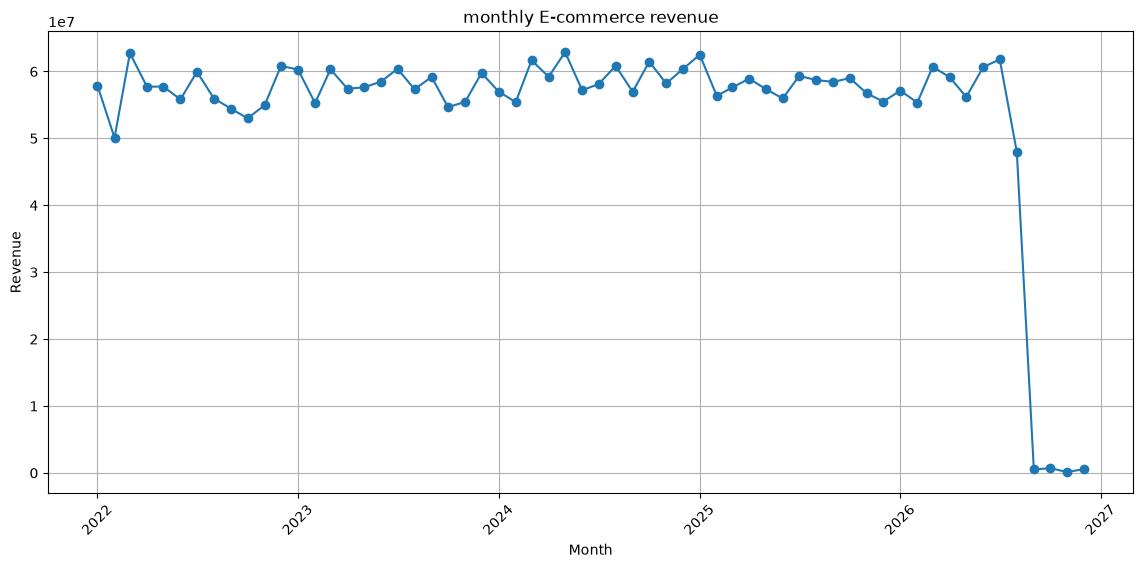

In [104]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14,6))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker='o'
)

plt.title('monthly E-commerce revenue')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)

plt.grid(True)
# plt.tight_layout()
plt.show


In [105]:
revenue_each_day=time_df['total_amount'].resample('D').sum()
revenue_each_day.head(12)

order_date
2022-01-01   2,869,699.15
2022-01-02   1,448,455.37
2022-01-03   1,672,624.63
2022-01-04   1,940,130.94
2022-01-05   1,915,934.83
2022-01-06   1,243,253.43
2022-01-07   2,122,654.89
2022-01-08     841,283.72
2022-01-09   3,205,740.20
2022-01-10   1,852,873.34
2022-01-11   1,388,754.85
2022-01-12   3,055,246.31
Freq: D, Name: total_amount, dtype: float64

In [106]:
revenue_each_month=time_df['total_amount'].resample('MS').sum()
revenue_each_month.head(12)

order_date
2022-01-01   57,885,215.01
2022-02-01   50,086,179.64
2022-03-01   62,725,073.77
2022-04-01   57,737,534.95
2022-05-01   57,727,630.62
2022-06-01   55,820,526.06
2022-07-01   59,956,441.45
2022-08-01   55,947,545.29
2022-09-01   54,441,522.37
2022-10-01   52,998,661.55
2022-11-01   54,928,980.70
2022-12-01   60,827,756.62
Freq: MS, Name: total_amount, dtype: float64

In [107]:
revenue_each_quarter=time_df['total_amount'].resample('QS').sum()
revenue_each_quarter.head(12)

order_date
2022-01-01   170,696,468.43
2022-04-01   171,285,691.63
2022-07-01   170,345,509.10
2022-10-01   168,755,398.88
2023-01-01   175,874,612.26
2023-04-01   173,515,700.47
2023-07-01   176,898,787.89
2023-10-01   169,885,807.03
2024-01-01   174,062,655.38
2024-04-01   179,284,755.87
2024-07-01   175,901,017.59
2024-10-01   180,003,402.81
Freq: QS-JAN, Name: total_amount, dtype: float64

In [108]:
monthly_revenue.idxmax()

Timestamp('2024-05-01 00:00:00')

In [109]:
monthly_revenue_with_unique_customer=time_df.resample('MS').agg(
    monthly_rev=('total_amount','sum'),
    unique_cust=('customer_id','nunique')
)

monthly_revenue_with_unique_customer.head(12)

,monthly_rev,unique_cust
order_date,,
2022-01-01,"57,885,215.01",832
2022-02-01,"50,086,179.64",732
2022-03-01,"62,725,073.77",882
2022-04-01,"57,737,534.95",827
2022-05-01,"57,727,630.62",845
2022-06-01,"55,820,526.06",843
2022-07-01,"59,956,441.45",849
2022-08-01,"55,947,545.29",804
2022-09-01,"54,441,522.37",767


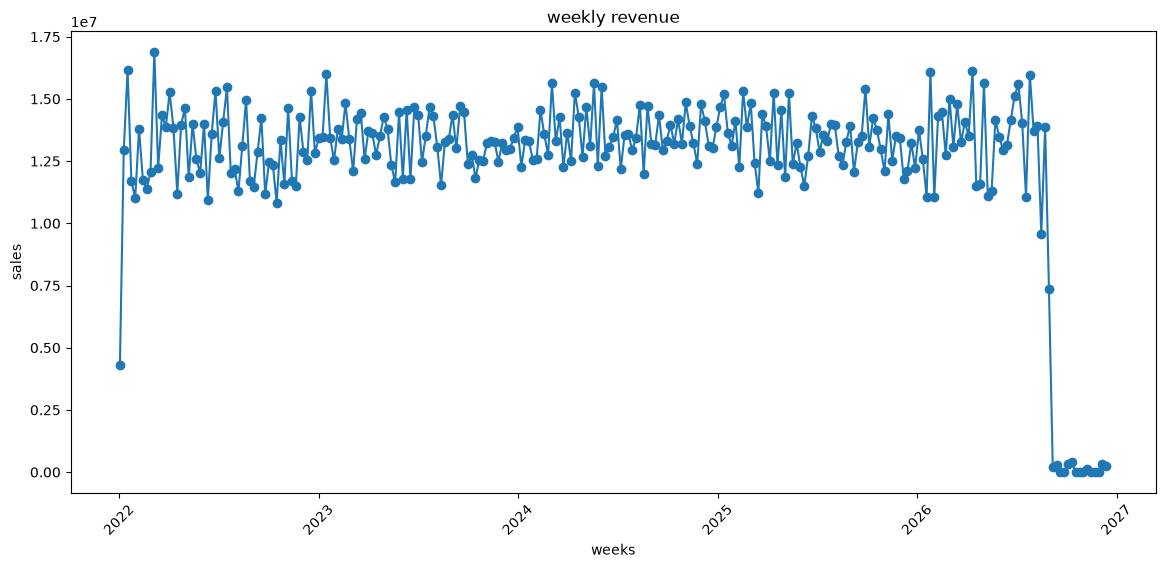

In [110]:
plt.figure(figsize=(14,6))
plt.plot(
    weekly_revenue.index,
    weekly_revenue.values,
    marker='o'
)

plt.xlabel('weeks')
plt.ylabel('sales')
plt.title('weekly revenue')
plt.xticks(rotation=45)
plt.show()

In [111]:
weekly_revenue.head()

order_date
2022-01-02    4,318,154.52
2022-01-09   12,941,622.64
2022-01-16   16,152,761.92
2022-01-23   11,702,998.43
2022-01-30   11,012,049.96
Freq: W-SUN, Name: total_amount, dtype: float64

In [112]:
monthly_kpi=time_df.resample('MS').agg(
    total_revenue=('total_amount','sum'),
    average_order_value=('total_amount', 'mean'),
    highest_order=('total_amount','max'),
    lowest_order=('total_amount','min'),
    total_order=('order_id','nunique'),
    unique_customer=('total_amount','nunique')
)
monthly_kpi.head(12)

,total_revenue,average_order_value,highest_order,lowest_order,total_order,unique_customer
order_date,,,,,,
2022-01-01,"57,885,215.01","64,532.01","276,639.72",854.58,897,897
2022-02-01,"50,086,179.64","63,080.83","257,699.20",595.27,794,794
2022-03-01,"62,725,073.77","66,235.56","260,485.23",826.92,947,947
2022-04-01,"57,737,534.95","65,536.36","249,056.69",994.12,881,881
2022-05-01,"57,727,630.62","63,717.03","265,836.31",872.01,906,906
2022-06-01,"55,820,526.06","61,885.28","272,144.10",776.86,902,902
2022-07-01,"59,956,441.45","66,470.56","277,483.99",749.91,902,902
2022-08-01,"55,947,545.29","64,233.69","246,483.18",742.81,871,871
2022-09-01,"54,441,522.37","64,966.02","261,045.20",803.52,838,838


In [113]:
# Month with highest revenue
best_month = monthly_kpi['total_revenue'].idxmax()

# Highest monthly revenue
highest_revenue = monthly_kpi['total_revenue'].max()

# Month with lowest revenue
worst_month = monthly_kpi['total_revenue'].idxmin()

# Lowest monthly revenue
lowest_revenue = monthly_kpi['total_revenue'].min()

print("Best month:", best_month)
print("Highest revenue:", highest_revenue)

print("Worst month:", worst_month)
print("Lowest revenue:", lowest_revenue)

Best month: 2024-05-01 00:00:00
Highest revenue: 62890177.52
Worst month: 2026-11-01 00:00:00
Lowest revenue: 114535.22


In [114]:
daily_sales=time_df['total_amount'].resample('D').sum()

daily_sales_revenue=daily_sales.rolling(window=2).sum()

# daily_sales_revenue=daily_sales.expanding().sum() # this also work same as rolling(windows=2)

daily_sales_7day=daily_sales.rolling(window=7).mean()

daily_sales_30day=daily_sales.rolling(window=30).mean()

daily_trend=pd.DataFrame(
    {
        'daily_revenue':daily_sales,
        'daily_sales_running_total':daily_sales_revenue,
        '7_day_average':daily_sales_7day,
        '30_day_average':daily_sales_30day
    }
)
daily_trend.head(35)

,daily_revenue,daily_sales_running_total,7_day_average,30_day_average
order_date,,,,
2022-01-01,"2,869,699.15",NaN,NaN,NaN
2022-01-02,"1,448,455.37","4,318,154.52",NaN,NaN
2022-01-03,"1,672,624.63","3,121,080.00",NaN,NaN
2022-01-04,"1,940,130.94","3,612,755.57",NaN,NaN
2022-01-05,"1,915,934.83","3,856,065.77",NaN,NaN
2022-01-06,"1,243,253.43","3,159,188.26",NaN,NaN
2022-01-07,"2,122,654.89","3,365,908.32","1,887,536.18",NaN
2022-01-08,"841,283.72","2,963,938.61","1,597,762.54",NaN
2022-01-09,"3,205,740.20","4,047,023.92","1,848,803.23",NaN


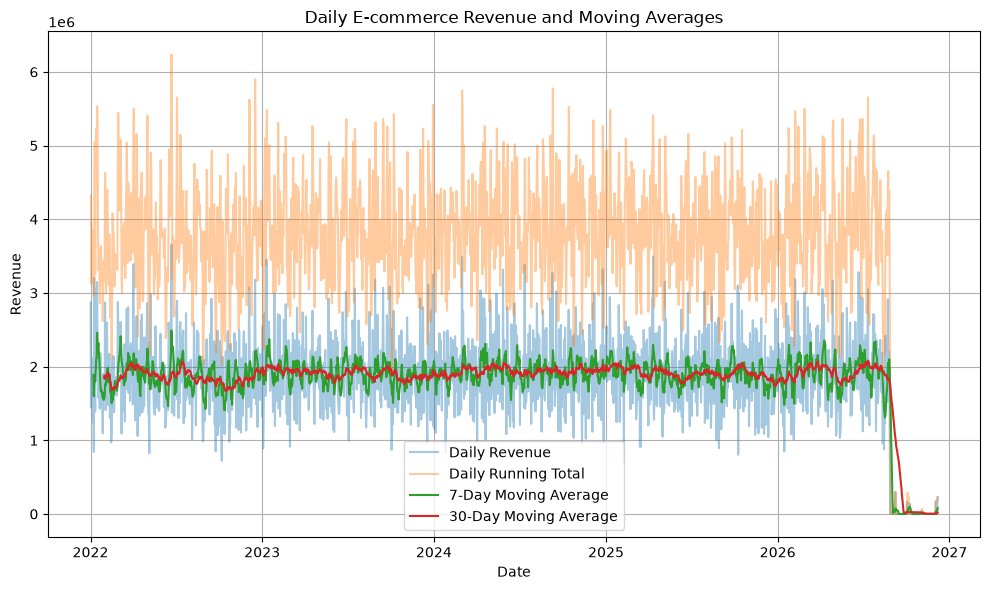

In [115]:
plt.figure(figsize=(10, 6))

plt.plot(
    daily_trend.index,
    daily_trend['daily_revenue'],
    label='Daily Revenue',
    alpha=0.4
)

plt.plot(
    daily_trend.index,
    daily_trend['daily_sales_running_total'],
    label='Daily Running Total',
    alpha=0.4
)

plt.plot(
    daily_trend.index,
    daily_trend['7_day_average'],
    label='7-Day Moving Average'
)

plt.plot(
    daily_trend.index,
    daily_trend['30_day_average'],
    label='30-Day Moving Average'
)

plt.title('Daily E-commerce Revenue and Moving Averages')
plt.xlabel('Date')
plt.ylabel('Revenue')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 10. Revenue Velocity Analysis: MoM, QoQ & YoY Growth Differencing
Evaluate revenue trajectories using lag differencing (`.shift(1)`, `.diff()`) and percentage change (`.pct_change() * 100`):
$$\text{MoM Growth (\%)} = \frac{\text{Revenue}_t - \text{Revenue}_{t-1}}{\text{Revenue}_{t-1}} \times 100$$
Identify highest growth periods, revenue contractions, and quarterly acceleration patterns.

In [116]:
# Exercise 1: Calculate monthly revenue, order count and unique customers.

exe1=time_df.resample('MS').agg(
    monthly_rev=('total_amount','sum'),
    order_count=('order_id','count'),
    unique_customer=('customer_id','nunique')
)
exe1.head(10)

,monthly_rev,order_count,unique_customer
order_date,,,
2022-01-01,"57,885,215.01",897,832
2022-02-01,"50,086,179.64",794,732
2022-03-01,"62,725,073.77",947,882
2022-04-01,"57,737,534.95",881,827
2022-05-01,"57,727,630.62",906,845
2022-06-01,"55,820,526.06",902,843
2022-07-01,"59,956,441.45",902,849
2022-08-01,"55,947,545.29",871,804
2022-09-01,"54,441,522.37",838,767


In [117]:
# Exercise 2: Find the top five months by revenue.

monthly_kpi.sort_values(
    'total_revenue',
    ascending=False
).head(5)

,total_revenue,average_order_value,highest_order,lowest_order,total_order,unique_customer
order_date,,,,,,
2024-05-01,"62,890,177.52","67,190.36","267,355.87",911.46,936,936
2022-03-01,"62,725,073.77","66,235.56","260,485.23",826.92,947,947
2025-01-01,"62,508,250.65","66,076.37","281,884.00",841.50,946,946
2026-07-01,"61,787,728.11","64,295.24","264,534.22",992.20,961,961
2024-03-01,"61,655,826.41","67,679.28","262,863.20",794.39,911,911


In [118]:
# Exercise 3: Find the month with the highest average order value.

monthly_kpi.sort_values(
    'average_order_value',
    ascending=False
).head(1)

,total_revenue,average_order_value,highest_order,lowest_order,total_order,unique_customer
order_date,,,,,,
2026-12-01,"571,404.85","95,234.14","128,905.87","42,200.10",6,6


In [119]:
bestmonth=monthly_kpi['average_order_value'].idxmax()
bestmonth

Timestamp('2026-12-01 00:00:00')

In [120]:
# Exercise 4: Calculate a 7-day rolling average of daily revenue.

daily = time_df['total_amount'].resample('D').sum()
runni = daily.rolling(window=7).mean()
runni.head(24)

# rollingavg7day=final_df['total_amount'].rolling(window=7).mean()
# rollingavg7day.head(24)

order_date
2022-01-01            NaN
2022-01-02            NaN
2022-01-03            NaN
2022-01-04            NaN
2022-01-05            NaN
2022-01-06            NaN
2022-01-07   1,887,536.18
2022-01-08   1,597,762.54
2022-01-09   1,848,803.23
2022-01-10   1,874,553.05
2022-01-11   1,795,785.04
2022-01-12   1,958,543.82
2022-01-13   2,091,945.29
2022-01-14   2,129,911.46
2022-01-15   2,459,364.49
2022-01-16   2,307,537.42
2022-01-17   2,290,612.92
2022-01-18   2,317,194.30
2022-01-19   2,151,669.57
2022-01-20   2,045,484.95
2022-01-21   1,908,180.32
2022-01-22   1,770,460.13
2022-01-23   1,671,856.92
2022-01-24   1,659,933.92
Freq: D, Name: total_amount, dtype: float64

In [121]:
# Exercise 5: Calculate a 14-day rolling average of daily revenue.

rolling_avg_14day=daily.rolling(window=14).mean()
rolling_avg_14day.head(28)

order_date
2022-01-01            NaN
2022-01-02            NaN
2022-01-03            NaN
2022-01-04            NaN
2022-01-05            NaN
2022-01-06            NaN
2022-01-07            NaN
2022-01-08            NaN
2022-01-09            NaN
2022-01-10            NaN
2022-01-11            NaN
2022-01-12            NaN
2022-01-13            NaN
2022-01-14   2,008,723.82
2022-01-15   2,028,563.52
2022-01-16   2,078,170.33
2022-01-17   2,082,582.98
2022-01-18   2,056,489.67
2022-01-19   2,055,106.70
2022-01-20   2,068,715.12
2022-01-21   2,019,045.89
2022-01-22   2,114,912.31
2022-01-23   1,989,697.17
2022-01-24   1,975,273.42
2022-01-25   1,995,542.61
2022-01-26   1,886,136.85
2022-01-27   1,808,772.27
2022-01-28   1,774,156.94
Freq: D, Name: total_amount, dtype: float64

In [122]:
# Exercise 6: Compare the 7-day and 30-day moving averages. What happens when the 7-day average is above the 30-day average?

# Exercise 7: Create a line chart comparing daily revenue with its 7-day moving average.

# Exercise 8: Calculate an expanding average of daily revenue.

In [123]:
check=pd.read_csv('orders_cleaned.csv')

In [124]:
check.head()

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source
0,ORD0000001,2025-12-11,CUST12577,PROD0232,2.00,"38,741.08",0.05,"71,452.04",WALLET,Delivered,Website,Mumbai,50.00,0,5.00,NONE,Android,Referral
1,ORD0000002,2026-06-04,CUST15421,PROD0317,3.00,"26,541.85",0.10,"71,662.99",NET BANKING,Cancelled,In-store,Chennai,28.00,0,5.00,NONE,Android,Search Ads
2,ORD0000003,2024-12-25,CUST14130,PROD0124,4.00,"11,645.74",0.20,"37,266.37",WALLET,Shipped,Marketplace,Hyderabad,34.00,0,4.00,WELCOME10,Android,Organic
3,ORD0000004,2023-02-04,CUST14117,PROD0012,4.00,"45,006.44",0.00,"180,025.77",CREDIT CARD,Delivered,Marketplace,Ranchi,25.00,0,5.00,NONE,Windows,Email
4,ORD0000005,2023-01-16,CUST13087,PROD0274,2.00,"43,124.43",0.25,"86,248.86",CREDIT CARD,Delivered,In-store,Chennai,33.00,0,2.00,NONE,Other,Social Media


In [125]:
check=check.sort_values('order_date')

In [126]:
check.head()

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source
37946,ORD0038215,2022-01-01,CUST12149,PROD0158,1.00,"31,010.12",0.10,"27,909.11",NET BANKING,Pending,In-store,Jaipur,18.00,0,5.00,NONE,Other,Organic
19724,ORD0019856,2022-01-01,CUST15203,PROD0143,5.00,"34,839.14",0.00,"174,195.70",NET BANKING,Delivered,In-store,Pune,67.00,0,3.00,FESTIVE20,iOS,Social Media
4212,ORD0004249,2022-01-01,CUST13389,PROD0112,1.00,"32,200.51",0.15,"27,370.43",NET BANKING,Returned,Mobile App,Bangalore,28.00,0,4.00,NONE,Windows,Social Media
29154,ORD0029354,2022-01-01,CUST15718,PROD0197,5.00,"47,029.03",0.05,"223,387.90",DEBIT CARD,Pending,Marketplace,Hyderabad,55.00,0,4.00,NONE,Windows,Search Ads
45077,ORD0045401,2022-01-01,CUST14108,PROD0021,5.00,"27,827.16",0.15,"118,265.45",UPI,Delivered,Mobile App,Chennai,25.00,0,5.00,NONE,Mac,Email


In [127]:
check=check.reset_index()

In [128]:
check.head()

,index,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source
0,37946,ORD0038215,2022-01-01,CUST12149,PROD0158,1.00,"31,010.12",0.10,"27,909.11",NET BANKING,Pending,In-store,Jaipur,18.00,0,5.00,NONE,Other,Organic
1,19724,ORD0019856,2022-01-01,CUST15203,PROD0143,5.00,"34,839.14",0.00,"174,195.70",NET BANKING,Delivered,In-store,Pune,67.00,0,3.00,FESTIVE20,iOS,Social Media
2,4212,ORD0004249,2022-01-01,CUST13389,PROD0112,1.00,"32,200.51",0.15,"27,370.43",NET BANKING,Returned,Mobile App,Bangalore,28.00,0,4.00,NONE,Windows,Social Media
3,29154,ORD0029354,2022-01-01,CUST15718,PROD0197,5.00,"47,029.03",0.05,"223,387.90",DEBIT CARD,Pending,Marketplace,Hyderabad,55.00,0,4.00,NONE,Windows,Search Ads
4,45077,ORD0045401,2022-01-01,CUST14108,PROD0021,5.00,"27,827.16",0.15,"118,265.45",UPI,Delivered,Mobile App,Chennai,25.00,0,5.00,NONE,Mac,Email


In [129]:
check=check.reset_index(drop=True)

In [130]:
check

,index,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source
0,37946,ORD0038215,2022-01-01,CUST12149,PROD0158,1.00,"31,010.12",0.10,"27,909.11",NET BANKING,Pending,In-store,Jaipur,18.00,0,5.00,NONE,Other,Organic
1,19724,ORD0019856,2022-01-01,CUST15203,PROD0143,5.00,"34,839.14",0.00,"174,195.70",NET BANKING,Delivered,In-store,Pune,67.00,0,3.00,FESTIVE20,iOS,Social Media
2,4212,ORD0004249,2022-01-01,CUST13389,PROD0112,1.00,"32,200.51",0.15,"27,370.43",NET BANKING,Returned,Mobile App,Bangalore,28.00,0,4.00,NONE,Windows,Social Media
3,29154,ORD0029354,2022-01-01,CUST15718,PROD0197,5.00,"47,029.03",0.05,"223,387.90",DEBIT CARD,Pending,Marketplace,Hyderabad,55.00,0,4.00,NONE,Windows,Search Ads
4,45077,ORD0045401,2022-01-01,CUST14108,PROD0021,5.00,"27,827.16",0.15,"118,265.45",UPI,Delivered,Mobile App,Chennai,25.00,0,5.00,NONE,Mac,Email
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49647,45536,ORD0045862,2026-12-03,CUST14420,PROD0206,4.00,"26,267.59",0.20,"84,056.28",DEBIT CARD,Delivered,In-store,Lucknow,31.00,0,4.00,NONE,Mac,Social Media
49648,14421,ORD0014515,2026-12-05,CUST10872,PROD0332,1.00,"42,200.10",0.10,"42,200.10",UPI,Delivered,Website,Hyderabad,72.00,0,5.00,FESTIVE20,Android,Search Ads
49649,43279,ORD0043581,2026-12-05,CUST10522,PROD0038,4.00,"37,913.49",0.15,"128,905.87",UPI,Delivered,Mobile App,Jaipur,46.00,0,4.00,NEWUSER,Mac,Search Ads
49650,39358,ORD0039633,2026-12-07,CUST13168,PROD0165,5.00,"23,638.71",0.10,"106,374.19",CASH,Delivered,In-store,Bangalore,58.00,0,5.00,FESTIVE20,Windows,Organic


In [131]:
check=check.drop(columns=['index'])

In [132]:
check

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source
0,ORD0038215,2022-01-01,CUST12149,PROD0158,1.00,"31,010.12",0.10,"27,909.11",NET BANKING,Pending,In-store,Jaipur,18.00,0,5.00,NONE,Other,Organic
1,ORD0019856,2022-01-01,CUST15203,PROD0143,5.00,"34,839.14",0.00,"174,195.70",NET BANKING,Delivered,In-store,Pune,67.00,0,3.00,FESTIVE20,iOS,Social Media
2,ORD0004249,2022-01-01,CUST13389,PROD0112,1.00,"32,200.51",0.15,"27,370.43",NET BANKING,Returned,Mobile App,Bangalore,28.00,0,4.00,NONE,Windows,Social Media
3,ORD0029354,2022-01-01,CUST15718,PROD0197,5.00,"47,029.03",0.05,"223,387.90",DEBIT CARD,Pending,Marketplace,Hyderabad,55.00,0,4.00,NONE,Windows,Search Ads
4,ORD0045401,2022-01-01,CUST14108,PROD0021,5.00,"27,827.16",0.15,"118,265.45",UPI,Delivered,Mobile App,Chennai,25.00,0,5.00,NONE,Mac,Email
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49647,ORD0045862,2026-12-03,CUST14420,PROD0206,4.00,"26,267.59",0.20,"84,056.28",DEBIT CARD,Delivered,In-store,Lucknow,31.00,0,4.00,NONE,Mac,Social Media
49648,ORD0014515,2026-12-05,CUST10872,PROD0332,1.00,"42,200.10",0.10,"42,200.10",UPI,Delivered,Website,Hyderabad,72.00,0,5.00,FESTIVE20,Android,Search Ads
49649,ORD0043581,2026-12-05,CUST10522,PROD0038,4.00,"37,913.49",0.15,"128,905.87",UPI,Delivered,Mobile App,Jaipur,46.00,0,4.00,NEWUSER,Mac,Search Ads
49650,ORD0039633,2026-12-07,CUST13168,PROD0165,5.00,"23,638.71",0.10,"106,374.19",CASH,Delivered,In-store,Bangalore,58.00,0,5.00,FESTIVE20,Windows,Organic


In [133]:
monthly_sales=time_df['total_amount'].resample('MS').sum()

monthly_sales=monthly_sales.to_frame(name='revenue')

monthly_sales.head(13)

,revenue
order_date,
2022-01-01,"57,885,215.01"
2022-02-01,"50,086,179.64"
2022-03-01,"62,725,073.77"
2022-04-01,"57,737,534.95"
2022-05-01,"57,727,630.62"
2022-06-01,"55,820,526.06"
2022-07-01,"59,956,441.45"
2022-08-01,"55,947,545.29"
2022-09-01,"54,441,522.37"


In [134]:
# Previous month's revenue
monthly_sales['previous_month'] = monthly_sales['revenue'].shift(1)

# Two months before
monthly_sales['two_months_before'] = monthly_sales['revenue'].shift(2)

# Next month's revenue
monthly_sales['next_month'] = monthly_sales['revenue'].shift(-1)

monthly_sales.head(12)

,revenue,previous_month,two_months_before,next_month
order_date,,,,
2022-01-01,"57,885,215.01",NaN,NaN,"50,086,179.64"
2022-02-01,"50,086,179.64","57,885,215.01",NaN,"62,725,073.77"
2022-03-01,"62,725,073.77","50,086,179.64","57,885,215.01","57,737,534.95"
2022-04-01,"57,737,534.95","62,725,073.77","50,086,179.64","57,727,630.62"
2022-05-01,"57,727,630.62","57,737,534.95","62,725,073.77","55,820,526.06"
2022-06-01,"55,820,526.06","57,727,630.62","57,737,534.95","59,956,441.45"
2022-07-01,"59,956,441.45","55,820,526.06","57,727,630.62","55,947,545.29"
2022-08-01,"55,947,545.29","59,956,441.45","55,820,526.06","54,441,522.37"
2022-09-01,"54,441,522.37","55,947,545.29","59,956,441.45","52,998,661.55"


In [135]:
monthly_sales['revenue_difference']=monthly_sales['revenue'].diff()
monthly_sales.head(12)

,revenue,previous_month,two_months_before,next_month,revenue_difference
order_date,,,,,
2022-01-01,"57,885,215.01",NaN,NaN,"50,086,179.64",NaN
2022-02-01,"50,086,179.64","57,885,215.01",NaN,"62,725,073.77","-7,799,035.37"
2022-03-01,"62,725,073.77","50,086,179.64","57,885,215.01","57,737,534.95","12,638,894.13"
2022-04-01,"57,737,534.95","62,725,073.77","50,086,179.64","57,727,630.62","-4,987,538.82"
2022-05-01,"57,727,630.62","57,737,534.95","62,725,073.77","55,820,526.06","-9,904.33"
2022-06-01,"55,820,526.06","57,727,630.62","57,737,534.95","59,956,441.45","-1,907,104.56"
2022-07-01,"59,956,441.45","55,820,526.06","57,727,630.62","55,947,545.29","4,135,915.38"
2022-08-01,"55,947,545.29","59,956,441.45","55,820,526.06","54,441,522.37","-4,008,896.16"
2022-09-01,"54,441,522.37","55,947,545.29","59,956,441.45","52,998,661.55","-1,506,022.92"


In [136]:
monthly_sales['percentage_change']=monthly_sales['revenue'].pct_change()*100
monthly_sales.head()

,revenue,previous_month,two_months_before,next_month,revenue_difference,percentage_change
order_date,,,,,,
2022-01-01,"57,885,215.01",NaN,NaN,"50,086,179.64",NaN,NaN
2022-02-01,"50,086,179.64","57,885,215.01",NaN,"62,725,073.77","-7,799,035.37",-13.47
2022-03-01,"62,725,073.77","50,086,179.64","57,885,215.01","57,737,534.95","12,638,894.13",25.23
2022-04-01,"57,737,534.95","62,725,073.77","50,086,179.64","57,727,630.62","-4,987,538.82",-7.95
2022-05-01,"57,727,630.62","57,737,534.95","62,725,073.77","55,820,526.06","-9,904.33",-0.02


In [137]:
# Create a copy
mom_analysis = monthly_sales[['revenue']].copy()

# Previous month's revenue
mom_analysis['previous_month_revenue'] = (
    mom_analysis['revenue'].shift(1)
)

# Revenue difference
mom_analysis['revenue_difference'] = (
    mom_analysis['revenue'].diff()
)

# Month-over-month growth
mom_analysis['mom_growth'] = (
    mom_analysis['revenue'].pct_change() * 100
)

mom_analysis.head(12)

,revenue,previous_month_revenue,revenue_difference,mom_growth
order_date,,,,
2022-01-01,"57,885,215.01",NaN,NaN,NaN
2022-02-01,"50,086,179.64","57,885,215.01","-7,799,035.37",-13.47
2022-03-01,"62,725,073.77","50,086,179.64","12,638,894.13",25.23
2022-04-01,"57,737,534.95","62,725,073.77","-4,987,538.82",-7.95
2022-05-01,"57,727,630.62","57,737,534.95","-9,904.33",-0.02
2022-06-01,"55,820,526.06","57,727,630.62","-1,907,104.56",-3.30
2022-07-01,"59,956,441.45","55,820,526.06","4,135,915.38",7.41
2022-08-01,"55,947,545.29","59,956,441.45","-4,008,896.16",-6.69
2022-09-01,"54,441,522.37","55,947,545.29","-1,506,022.92",-2.69


In [138]:
# Quarterly revenue
quarterly_sales = (
    time_df['total_amount']
    .resample('QS')
    .sum()
)

# Quarterly growth
quarterly_sales_df = quarterly_sales.to_frame(name='revenue')

quarterly_sales_df['previous_quarter'] = (
    quarterly_sales_df['revenue'].shift(1)
)

quarterly_sales_df['qoq_growth'] = (
    quarterly_sales_df['revenue'].pct_change() * 100
)


# Yearly revenue
yearly_sales = (
    time_df['total_amount']
    .resample('YS')
    .sum()
)

yearly_sales_df = yearly_sales.to_frame(name='revenue')

yearly_sales_df['previous_year'] = (
    yearly_sales_df['revenue'].shift(1)
)

yearly_sales_df['yoy_growth'] = (
    yearly_sales_df['revenue'].pct_change() * 100
)

In [139]:
yearly_sales_df.head()

,revenue,previous_year,yoy_growth
order_date,,,
2022-01-01,"681,083,068.04",NaN,NaN
2023-01-01,"696,174,907.66","681,083,068.04",2.22
2024-01-01,"709,251,831.66","696,174,907.66",1.88
2025-01-01,"696,430,837.83","709,251,831.66",-1.81
2026-01-01,"460,822,117.31","696,430,837.83",-33.83


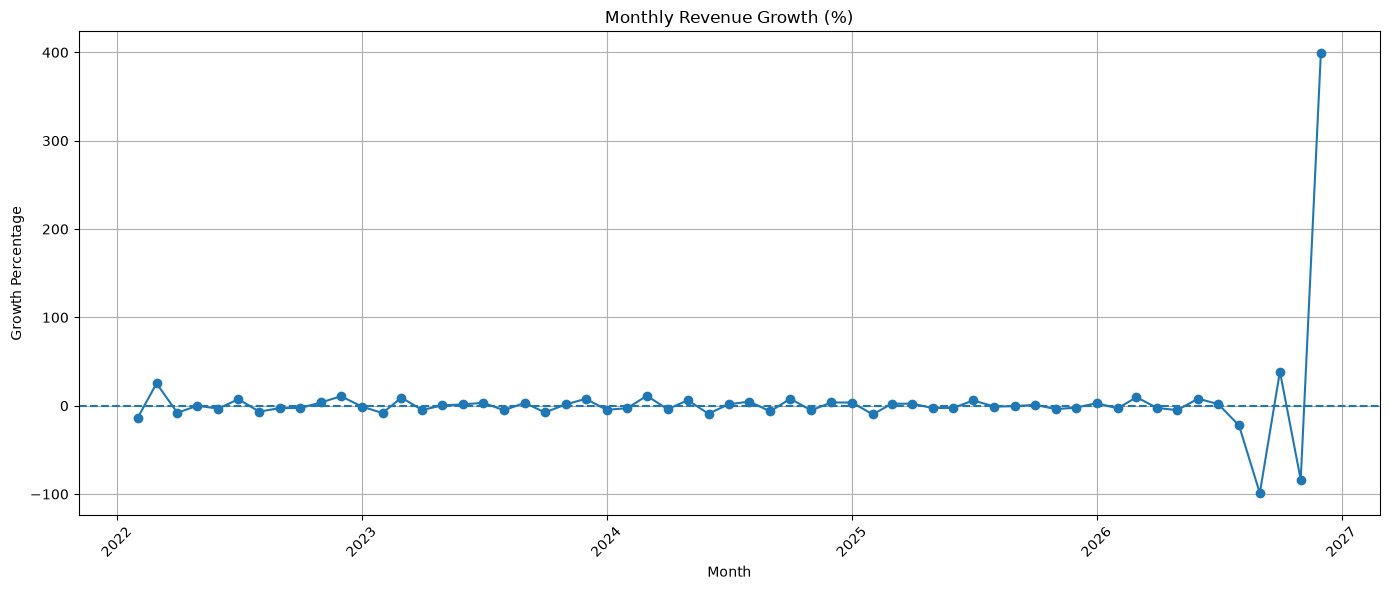

In [140]:
plt.figure(figsize=(14, 6))

plt.plot(
    mom_analysis.index,
    mom_analysis['mom_growth'],
    marker='o'
)

plt.axhline(y=0, linestyle='--')

plt.title('Monthly Revenue Growth (%)')
plt.xlabel('Month')
plt.ylabel('Growth Percentage')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [141]:
month_rev=time_df['total_amount'].resample('MS').sum()
month_rev=month_rev.to_frame(name='revenue')

month_rev.head()

,revenue
order_date,
2022-01-01,"57,885,215.01"
2022-02-01,"50,086,179.64"
2022-03-01,"62,725,073.77"
2022-04-01,"57,737,534.95"
2022-05-01,"57,727,630.62"


In [142]:
month_rev

,revenue
order_date,
2022-01-01,"57,885,215.01"
2022-02-01,"50,086,179.64"
2022-03-01,"62,725,073.77"
2022-04-01,"57,737,534.95"
2022-05-01,"57,727,630.62"
2022-06-01,"55,820,526.06"
2022-07-01,"59,956,441.45"
2022-08-01,"55,947,545.29"
2022-09-01,"54,441,522.37"


In [143]:
month_rev['rev_diff']=month_rev['revenue'].diff()
month_rev

,revenue,rev_diff
order_date,,
2022-01-01,"57,885,215.01",NaN
2022-02-01,"50,086,179.64","-7,799,035.37"
2022-03-01,"62,725,073.77","12,638,894.13"
2022-04-01,"57,737,534.95","-4,987,538.82"
2022-05-01,"57,727,630.62","-9,904.33"
2022-06-01,"55,820,526.06","-1,907,104.56"
2022-07-01,"59,956,441.45","4,135,915.38"
2022-08-01,"55,947,545.29","-4,008,896.16"
2022-09-01,"54,441,522.37","-1,506,022.92"


In [144]:
month_rev['mom growth']=month_rev['revenue'].pct_change()*100

month_rev

,revenue,rev_diff,mom growth
order_date,,,
2022-01-01,"57,885,215.01",NaN,NaN
2022-02-01,"50,086,179.64","-7,799,035.37",-13.47
2022-03-01,"62,725,073.77","12,638,894.13",25.23
2022-04-01,"57,737,534.95","-4,987,538.82",-7.95
2022-05-01,"57,727,630.62","-9,904.33",-0.02
2022-06-01,"55,820,526.06","-1,907,104.56",-3.30
2022-07-01,"59,956,441.45","4,135,915.38",7.41
2022-08-01,"55,947,545.29","-4,008,896.16",-6.69
2022-09-01,"54,441,522.37","-1,506,022.92",-2.69


In [145]:
month_rev['mom growth'].idxmax()

Timestamp('2026-12-01 00:00:00')

In [146]:
month_rev['mom growth'].idxmin()

Timestamp('2026-09-01 00:00:00')

In [147]:
quarterly_sales=time_df['total_amount'].resample('QS').sum()
quarterly_sales

order_date
2022-01-01   170,696,468.43
2022-04-01   171,285,691.63
2022-07-01   170,345,509.10
2022-10-01   168,755,398.88
2023-01-01   175,874,612.26
2023-04-01   173,515,700.47
2023-07-01   176,898,787.89
2023-10-01   169,885,807.03
2024-01-01   174,062,655.38
2024-04-01   179,284,755.87
2024-07-01   175,901,017.59
2024-10-01   180,003,402.81
2025-01-01   176,460,671.13
2025-04-01   172,255,996.79
2025-07-01   176,477,443.16
2025-10-01   171,236,726.74
2026-01-01   173,184,574.37
2026-04-01   175,983,984.47
2026-07-01   110,262,863.05
2026-10-01     1,390,695.42
Freq: QS-JAN, Name: total_amount, dtype: float64

In [148]:
quarterly_sales_df=quarterly_sales.to_frame(name='revenue')

quarterly_sales_df.head(1)

,revenue
order_date,
2022-01-01,"170,696,468.43"


In [149]:
quarterly_sales_df['previous_quartes']=quarterly_sales_df['revenue'].shift(1)
quarterly_sales_df.head(4)

,revenue,previous_quartes
order_date,,
2022-01-01,"170,696,468.43",NaN
2022-04-01,"171,285,691.63","170,696,468.43"
2022-07-01,"170,345,509.10","171,285,691.63"
2022-10-01,"168,755,398.88","170,345,509.10"


In [150]:
quarterly_sales_df['revenue_diff']=quarterly_sales_df['revenue'].diff()
quarterly_sales_df.head(5)

,revenue,previous_quartes,revenue_diff
order_date,,,
2022-01-01,"170,696,468.43",NaN,NaN
2022-04-01,"171,285,691.63","170,696,468.43","589,223.21"
2022-07-01,"170,345,509.10","171,285,691.63","-940,182.53"
2022-10-01,"168,755,398.88","170,345,509.10","-1,590,110.22"
2023-01-01,"175,874,612.26","168,755,398.88","7,119,213.38"


In [151]:
quarterly_sales_df['qoq growth']=quarterly_sales_df['revenue'].pct_change()*100

quarterly_sales_df

,revenue,previous_quartes,revenue_diff,qoq growth
order_date,,,,
2022-01-01,"170,696,468.43",NaN,NaN,NaN
2022-04-01,"171,285,691.63","170,696,468.43","589,223.21",0.35
2022-07-01,"170,345,509.10","171,285,691.63","-940,182.53",-0.55
2022-10-01,"168,755,398.88","170,345,509.10","-1,590,110.22",-0.93
2023-01-01,"175,874,612.26","168,755,398.88","7,119,213.38",4.22
2023-04-01,"173,515,700.47","175,874,612.26","-2,358,911.79",-1.34
2023-07-01,"176,898,787.89","173,515,700.47","3,383,087.41",1.95
2023-10-01,"169,885,807.03","176,898,787.89","-7,012,980.86",-3.96
2024-01-01,"174,062,655.38","169,885,807.03","4,176,848.35",2.46


In [152]:
yearly_rev=time_df['total_amount'].resample('YS').sum()

yearly_rev

# yearly_reev=time_df['total_amount'].resample('YS').sum().pct_change()*100

# yearly_reev

order_date
2022-01-01   681,083,068.04
2023-01-01   696,174,907.66
2024-01-01   709,251,831.66
2025-01-01   696,430,837.83
2026-01-01   460,822,117.31
Freq: YS-JAN, Name: total_amount, dtype: float64

In [153]:
yearly_revenue_df=yearly_rev.to_frame(name='revenue')

yearly_revenue_df

,revenue
order_date,
2022-01-01,"681,083,068.04"
2023-01-01,"696,174,907.66"
2024-01-01,"709,251,831.66"
2025-01-01,"696,430,837.83"
2026-01-01,"460,822,117.31"


In [154]:
yearly_revenue_df['yearly diff']=yearly_revenue_df['revenue'].diff()
yearly_revenue_df['yearly pct change']=yearly_revenue_df['revenue'].pct_change()*100

yearly_revenue_df

,revenue,yearly diff,yearly pct change
order_date,,,
2022-01-01,"681,083,068.04",NaN,NaN
2023-01-01,"696,174,907.66","15,091,839.62",2.22
2024-01-01,"709,251,831.66","13,076,924.00",1.88
2025-01-01,"696,430,837.83","-12,820,993.83",-1.81
2026-01-01,"460,822,117.31","-235,608,720.52",-33.83


In [155]:
# Highest growth
mom_analysis['mom_growth'].idxmax()

# Largest decline
mom_analysis['mom_growth'].idxmin()

# Maximum growth percentage
mom_analysis['mom_growth'].max()

# Minimum growth percentage
mom_analysis['mom_growth'].min()

np.float64(-98.94054260949457)

## 11. Trend Smoothing: 3-Month & 6-Month Rolling Moving Averages
Raw monthly revenue exhibits high noise. Apply rolling moving averages (`.rolling(window=3).mean()`, `.rolling(window=6).mean()`) to isolate underlying structural revenue trends from short-term fluctuations.

In [156]:

# Calculate monthly revenue
monthly_revenue=time_df['total_amount'].resample('MS').sum()

# Convert Series into DataFrame
monthly_revenue_df=monthly_revenue.to_frame(name='revenue')

# Display the result
monthly_revenue_df.head()

,revenue
order_date,
2022-01-01,"57,885,215.01"
2022-02-01,"50,086,179.64"
2022-03-01,"62,725,073.77"
2022-04-01,"57,737,534.95"
2022-05-01,"57,727,630.62"


In [157]:
print('start date:' , monthly_revenue_df.index.min())
print('end date', monthly_revenue_df.index.max())

print('missing values')
print(monthly_revenue_df.isnull().sum())

start date: 2022-01-01 00:00:00
end date 2026-12-01 00:00:00
missing values
revenue    0
dtype: int64


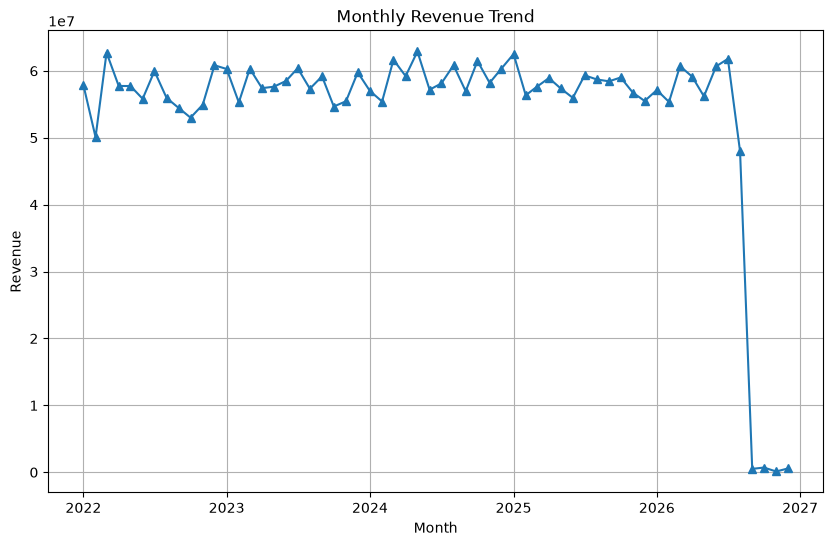

In [197]:
# trend analysis using line chart

plt.figure(figsize=(10,6))

plt.plot(
    monthly_revenue_df.index,
    monthly_revenue_df['revenue'],
    label='Monthlly Revenue',
    marker='^'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
# plt.legend()
plt.grid(True)
plt.show()



In [159]:
monthly_revenue_df['3_month_trend']=monthly_revenue_df['revenue'].rolling(window=3).mean()

monthly_revenue_df['6_month_trend']=monthly_revenue_df['revenue'].rolling(window=6).mean()

monthly_revenue_df.head(12)

,revenue,3_month_trend,6_month_trend
order_date,,,
2022-01-01,"57,885,215.01",NaN,NaN
2022-02-01,"50,086,179.64",NaN,NaN
2022-03-01,"62,725,073.77","56,898,822.81",NaN
2022-04-01,"57,737,534.95","56,849,596.12",NaN
2022-05-01,"57,727,630.62","59,396,746.45",NaN
2022-06-01,"55,820,526.06","57,095,230.54","56,997,026.68"
2022-07-01,"59,956,441.45","57,834,866.04","57,342,231.08"
2022-08-01,"55,947,545.29","57,241,504.27","58,319,125.36"
2022-09-01,"54,441,522.37","56,781,836.37","56,938,533.46"


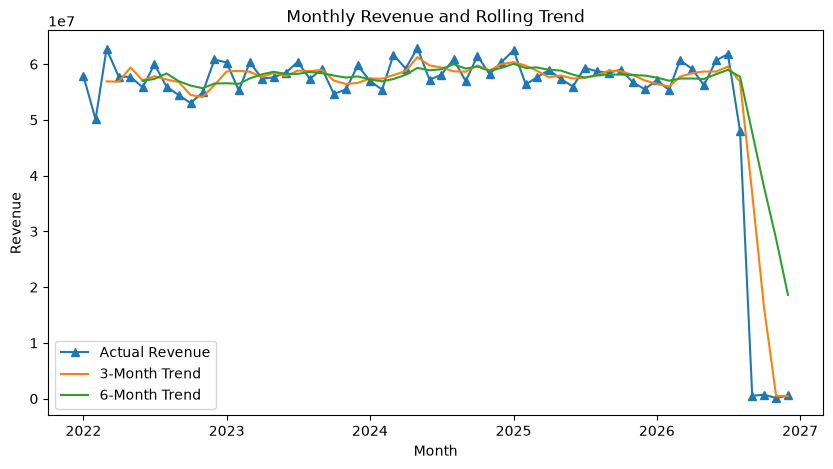

In [196]:
plt.figure(figsize=(10,5))

plt.plot(
    monthly_revenue_df.index,
    monthly_revenue_df['revenue'],
    label='Actual Revenue',
    marker='^',
    # alpha=0.5
)

plt.plot(
    monthly_revenue_df.index,
    monthly_revenue_df['3_month_trend'],
    label='3-Month Trend'
)

plt.plot(
    monthly_revenue_df.index,
    monthly_revenue_df['6_month_trend'],
    label='6-Month Trend'
)

plt.xlabel('Month')
plt.title('Monthly Revenue and Rolling Trend')
plt.ylabel('Revenue')
plt.legend()
plt.show()


In [161]:
monthly_revenue_df['month_number'] = monthly_revenue_df.index.month

seasonal_month = (
    monthly_revenue_df
    .groupby('month_number')['revenue']
    .mean()
)

seasonal_month
 

month_number
1    58,957,980.96
2    54,494,821.31
3    60,602,994.05
4    58,482,187.38
5    58,359,941.16
6    57,623,097.30
7    59,916,526.70
8    56,157,460.96
9    45,903,136.49
10   45,768,674.34
11   45,086,274.95
12   47,399,456.88
Name: revenue, dtype: float64

In [162]:
overall_mean=seasonal_month.mean()
seasonal_index=seasonal_month/overall_mean
seasonal_index

month_number
1    1.09
2    1.01
3    1.12
4    1.08
5    1.08
6    1.07
7    1.11
8    1.04
9    0.85
10   0.85
11   0.83
12   0.88
Name: revenue, dtype: float64

In [163]:
seasonal_month

month_number
1    58,957,980.96
2    54,494,821.31
3    60,602,994.05
4    58,482,187.38
5    58,359,941.16
6    57,623,097.30
7    59,916,526.70
8    56,157,460.96
9    45,903,136.49
10   45,768,674.34
11   45,086,274.95
12   47,399,456.88
Name: revenue, dtype: float64

[]

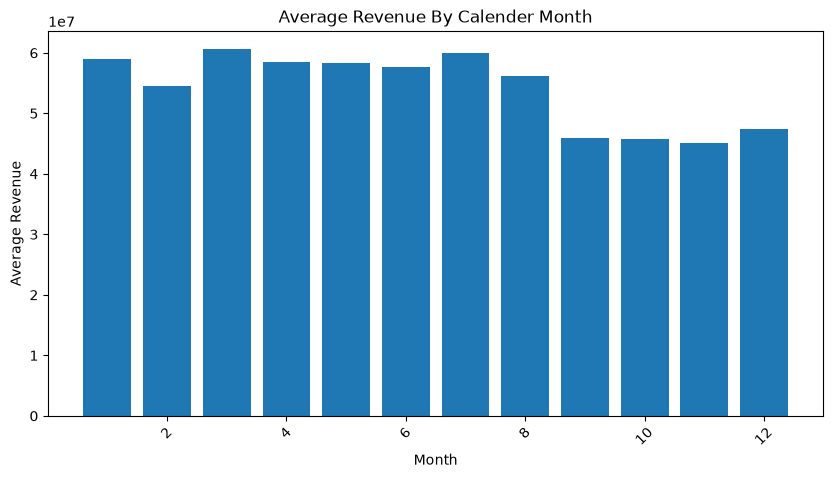

In [164]:
plt.figure(figsize=(10,5))

plt.bar(
    seasonal_month.index,
    seasonal_month.values
)

plt.title('Average Revenue By Calender Month')
plt.xlabel('Month')
plt.ylabel('Average Revenue')
plt.xticks(rotation=45)
# plt.legend()
plt.plot()

## 12. Seasonality Modeling & Day-of-Week Purchasing Patterns
Analyze day-of-week purchasing patterns (`index.weekday`) and calculate monthly seasonal indices:
$$\text{Seasonal Index}_m = \frac{\text{Mean Revenue}_m}{\text{Overall Mean Revenue}}$$

In [165]:
daily_rev=time_df['total_amount'].resample('D').sum()

weekday_revenue=daily_rev.groupby(daily_rev.index.dayofweek).mean()

weekday_revenue.index=[
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

weekday_revenue

Monday      1,782,546.16
Tuesday     1,836,206.94
Wednesday   1,797,097.83
Thursday    1,812,625.47
Friday      1,787,999.32
Saturday    1,796,169.02
Sunday      1,788,117.63
Name: total_amount, dtype: float64

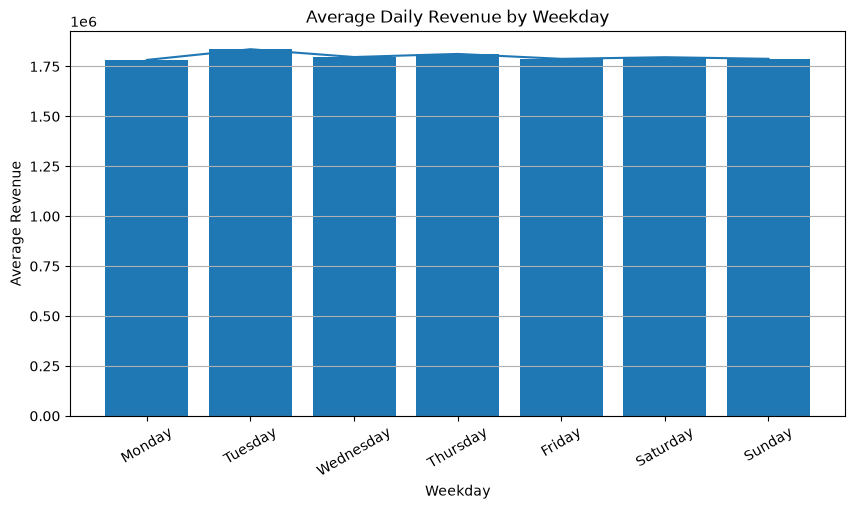

In [195]:
plt.figure(figsize=(10, 5))

plt.bar(
    weekday_revenue.index,
    weekday_revenue.values
)

plt.plot(
    weekday_revenue.index,
    weekday_revenue.values
)

plt.title('Average Daily Revenue by Weekday')
plt.xlabel('Weekday')
plt.ylabel('Average Revenue')
plt.xticks(rotation=30)
plt.grid(axis='y')

plt.show()

## 13. Time-Series Seasonal Decomposition (`seasonal_decompose`)
Decompose monthly revenue into its three constituent mathematical components using an additive model:
$$Y_t = T_t + S_t + R_t$$
where:
- $T_t$ = Underlying Trend component
- $S_t$ = Repeating Seasonal cycle
- $R_t$ = Unexplained Residual noise / irregularities

In [167]:
from statsmodels.tsa.seasonal import seasonal_decompose

In [168]:
decompose_data=monthly_revenue_df['revenue'].copy()

In [169]:
decompose_data=decompose_data.asfreq('MS')

print(decompose_data.isnull().sum())

0


In [170]:
decomposition=seasonal_decompose(
    decompose_data,
    model='additive',
    period=12
)

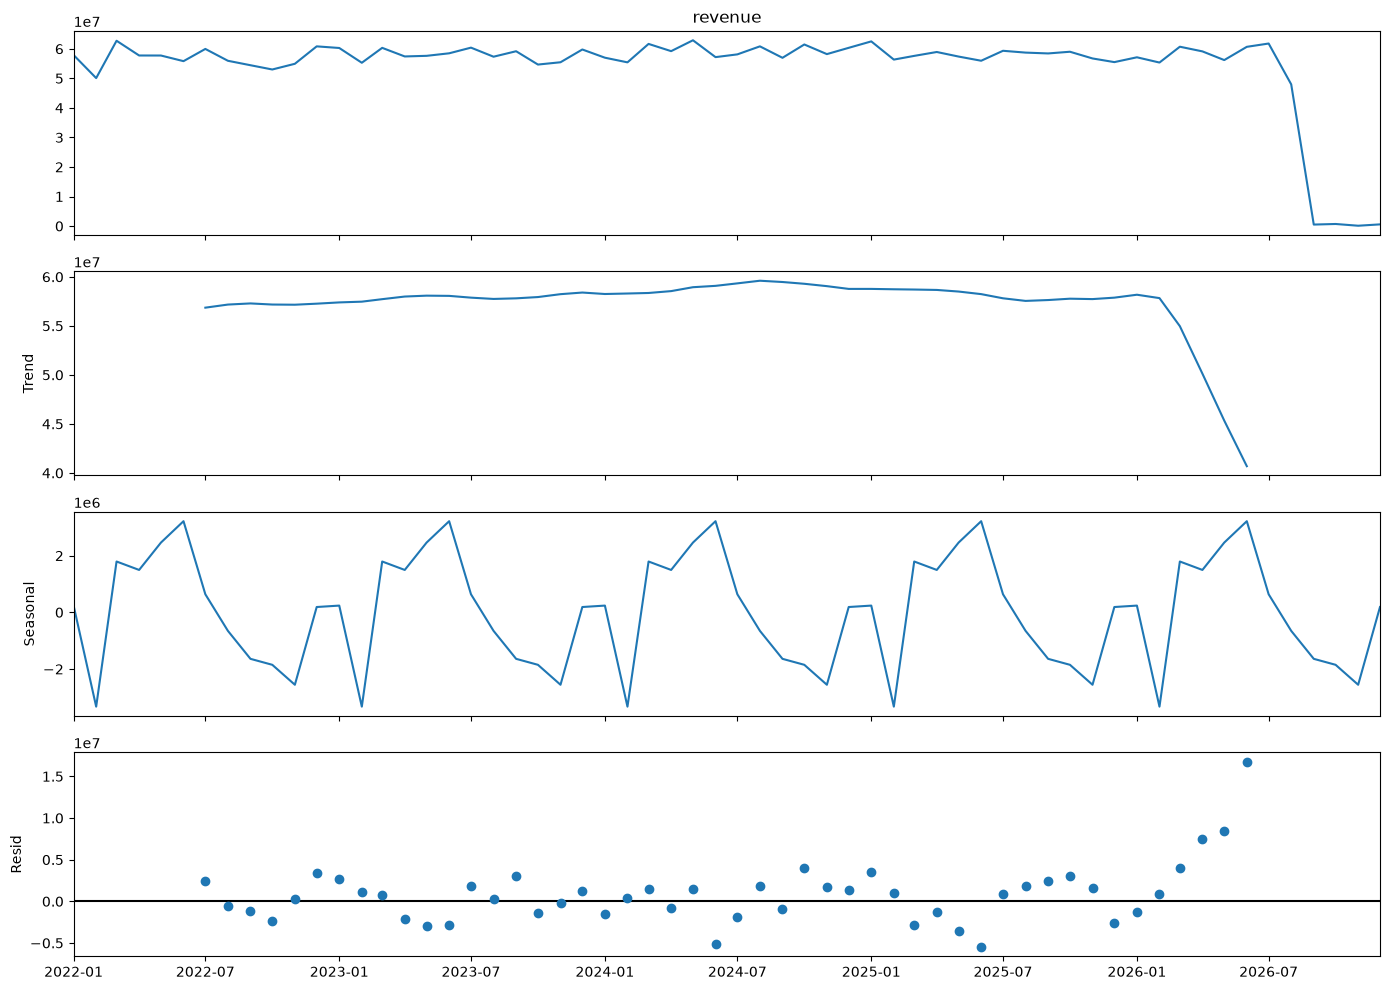

In [171]:
fig=decomposition.plot()
fig.set_size_inches(14,10)
plt.tight_layout()
plt.show()

## 14. Statistical Anomaly Detection: IQR & Z-Score Frameworks
Evaluate daily revenue streams for abnormal spikes and flash drops using two rigorous statistical methods:
1. **Interquartile Range (IQR) Non-Parametric Method:**
   $$IQR = Q_3 - Q_1$$
   $$\text{Lower Bound} = Q_1 - 1.5 \times IQR, \quad \text{Upper Bound} = Q_3 + 1.5 \times IQR$$
2. **Z-Score Parametric Method ($|Z| > 3$):**
   $$Z = \frac{X - \mu}{\sigma}$$
   Flags data points deviating more than 3 standard deviations from the population mean ($99.7\%$ confidence interval).

In [172]:
daily_revenue=time_df['total_amount'].resample('D').sum()
anomly_df=daily_revenue.to_frame(name='revenue')
anomly_df.head()

,revenue
order_date,
2022-01-01,"2,869,699.15"
2022-01-02,"1,448,455.37"
2022-01-03,"1,672,624.63"
2022-01-04,"1,940,130.94"
2022-01-05,"1,915,934.83"


In [173]:
anomly_df['revenue'].describe()

count       1,802.00
mean    1,800,090.32
std       627,860.94
min             0.00
25%     1,522,162.22
50%     1,839,144.57
75%     2,168,632.97
max     3,657,961.03
Name: revenue, dtype: float64

In [174]:
# calculate IQR

Q1=anomly_df['revenue'].quantile(0.25)
Q3=anomly_df['revenue'].quantile(0.75)

IQR=Q3-Q1

lower_bound=Q1-(1.5*IQR)
upper_bound=Q3+(1.5*IQR)

print('Q1:',Q1)
print('Q3:',Q3)
print('IQR:',IQR)
print('lower_bound:', lower_bound)
print('upper_bound:',upper_bound)

Q1: 1522162.2225000001
Q3: 2168632.9699999997
IQR: 646470.7474999996
lower_bound: 552456.1012500008
upper_bound: 3138339.091249999


In [175]:
anomly_df['is_anomly']=(
    (anomly_df['revenue']<lower_bound) | (anomly_df['revenue']>upper_bound)
)
anomly_df[anomly_df['is_anomly']].sample(10)

,revenue,is_anomly
order_date,,
2026-09-27,0.00,True
2026-10-03,"168,602.88",True
2026-11-09,0.00,True
2026-11-04,"33,721.45",True
2026-10-27,0.00,True
2026-09-29,0.00,True
2026-10-12,0.00,True
2026-09-08,"298,786.00",True
2022-01-09,"3,205,740.20",True


In [176]:
high_anomalies = anomly_df[
    anomly_df['revenue'] > upper_bound
]

low_anomalies = anomly_df[
    anomly_df['revenue'] < lower_bound
]

print("High anomalies:", len(high_anomalies))
print("Low anomalies:", len(low_anomalies))
print(anomly_df[anomly_df['revenue']==0].count())

High anomalies: 18
Low anomalies: 102
revenue      83
is_anomly    83
dtype: int64


In [177]:
monthly_revenue_d=monthly_revenue.copy()

In [178]:
monthly_revenue_d=monthly_revenue_d.to_frame(name='revenue')

In [179]:
monthly_revenue_d['3_month']=monthly_revenue_d['revenue'].rolling(window=3).mean()
monthly_revenue_d['6_month']=monthly_revenue_d['revenue'].rolling(window=6).mean()
monthly_revenue_d.head(10)

,revenue,3_month,6_month
order_date,,,
2022-01-01,"57,885,215.01",NaN,NaN
2022-02-01,"50,086,179.64",NaN,NaN
2022-03-01,"62,725,073.77","56,898,822.81",NaN
2022-04-01,"57,737,534.95","56,849,596.12",NaN
2022-05-01,"57,727,630.62","59,396,746.45",NaN
2022-06-01,"55,820,526.06","57,095,230.54","56,997,026.68"
2022-07-01,"59,956,441.45","57,834,866.04","57,342,231.08"
2022-08-01,"55,947,545.29","57,241,504.27","58,319,125.36"
2022-09-01,"54,441,522.37","56,781,836.37","56,938,533.46"


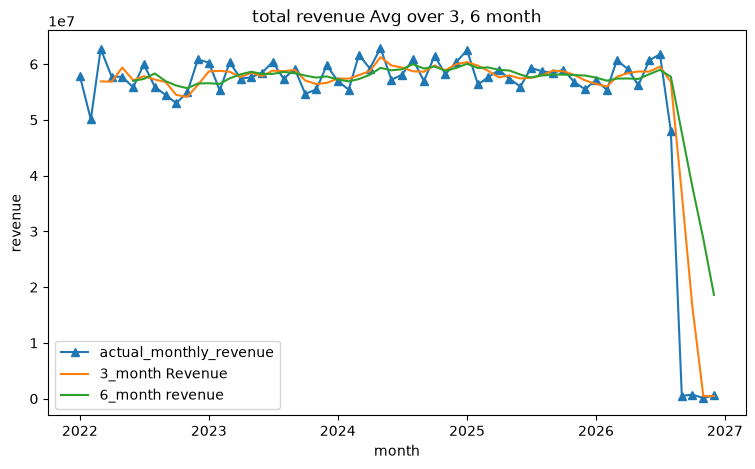

In [180]:
plt.figure(figsize=(9,5))

plt.plot(
    monthly_revenue_d.index,
    monthly_revenue_d['revenue'],
    label='actual_monthly_revenue',
    marker='^'
)

plt.plot(
    monthly_revenue_d.index,
    monthly_revenue_d['3_month'],
    label='3_month Revenue'
    
)

plt.plot(
    monthly_revenue_d.index,
    monthly_revenue_d['6_month'],
    label='6_month revenue'
)

plt.title('total revenue Avg over 3, 6 month')
plt.xlabel('month')
plt.ylabel('revenue')
plt.legend()
plt.show()


In [181]:
seasonal_month.sort_values(ascending=False).head(3)

month_number
3   60,602,994.05
7   59,916,526.70
1   58,957,980.96
Name: revenue, dtype: float64

In [182]:
monthly_revenue_df['week']=monthly_revenue_df.index.weekday

week_day=monthly_revenue_df.groupby('week')['revenue'].mean()

week_day
 

week
0   57,810,295.41
1   45,095,915.91
2   59,131,684.48
3   50,650,174.64
4   58,925,222.00
5   56,059,315.87
6   51,343,886.66
Name: revenue, dtype: float64

In [183]:
week_day.sort_values(ascending=False).head(1)

week
2   59,131,684.48
Name: revenue, dtype: float64

In [184]:
week_day.sort_values().head(1)

week
1   45,095,915.91
Name: revenue, dtype: float64

In [185]:
# Calculate daily revenue
daily_revenue = (
    time_df['total_amount']
    .resample('D')
    .sum()
)

# Convert to DataFrame
anomaly_df = daily_revenue.to_frame(name='revenue')

# Check the data
anomaly_df.head()

,revenue
order_date,
2022-01-01,"2,869,699.15"
2022-01-02,"1,448,455.37"
2022-01-03,"1,672,624.63"
2022-01-04,"1,940,130.94"
2022-01-05,"1,915,934.83"


In [186]:
Q1 = anomaly_df['revenue'].quantile(0.25)

Q3 = anomaly_df['revenue'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)

upper_bound = Q3 + (1.5 * IQR)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 1522162.2225000001
Q3: 2168632.9699999997
IQR: 646470.7474999996
Lower Bound: 552456.1012500008
Upper Bound: 3138339.091249999


In [187]:
anomaly_df['is_anomaly'] = (
    (anomaly_df['revenue'] < lower_bound) |
    (anomaly_df['revenue'] > upper_bound)
)

anomaly_df[anomaly_df['is_anomaly']]

,revenue,is_anomaly
order_date,,
2022-01-09,"3,205,740.20",True
2022-01-15,"3,147,454.91",True
2022-04-02,"3,390,766.77",True
2022-06-22,"3,657,961.03",True
2022-12-17,"3,179,964.45",True
...,...,...
2026-12-03,"172,159.43",True
2026-12-04,0.00,True
2026-12-05,"171,105.97",True


In [188]:
high_anomalies = anomaly_df[
    anomaly_df['revenue'] > upper_bound
]

low_anomalies = anomaly_df[
    anomaly_df['revenue'] < lower_bound
]

print("High anomalies:", len(high_anomalies))
print("Low anomalies:", len(low_anomalies))

High anomalies: 18
Low anomalies: 102


In [189]:
mean_revenue = anomaly_df['revenue'].mean()

std_revenue = anomaly_df['revenue'].std()

anomaly_df['z_score'] = (
    (anomaly_df['revenue'] - mean_revenue) /
    std_revenue
)

anomaly_df.head()

,revenue,is_anomaly,z_score
order_date,,,
2022-01-01,"2,869,699.15",False,1.70
2022-01-02,"1,448,455.37",False,-0.56
2022-01-03,"1,672,624.63",False,-0.20
2022-01-04,"1,940,130.94",False,0.22
2022-01-05,"1,915,934.83",False,0.18


In [190]:
z_anomalies = anomaly_df[
    anomaly_df['z_score'].abs() > 3
]

z_anomalies

,revenue,is_anomaly,z_score
order_date,,,


## 15. Dynamic Rolling Anomaly Detection & Comprehensive Visualization
Construct a localized dynamic anomaly detector using a trailing 30-day rolling window:
$$\text{Upper Threshold}_t = \mu_{\text{roll}, 30}(t-1) + 3 \times \sigma_{\text{roll}, 30}(t-1)$$
Plot the full timeline highlighting daily revenue, the dynamic threshold envelope, and all flagged anomaly events.

In [191]:
anomaly_df['rolling_mean'] = (
    anomaly_df['revenue']
    .shift(1)
    .rolling(window=7)
    .mean()
)

anomaly_df['rolling_std'] = (
    anomaly_df['revenue']
    .shift(1)
    .rolling(window=7)
    .std()
)

In [192]:
anomaly_df['rolling_upper'] = (
    anomaly_df['rolling_mean'] +
    (3 * anomaly_df['rolling_std'])
)

anomaly_df['rolling_lower'] = (
    anomaly_df['rolling_mean'] -
    (3 * anomaly_df['rolling_std'])
)

In [193]:
anomaly_df['rolling_anomaly'] = (
    (anomaly_df['revenue'] > anomaly_df['rolling_upper']) |
    (anomaly_df['revenue'] < anomaly_df['rolling_lower'])
)

rolling_anomalies = anomaly_df[
    anomaly_df['rolling_anomaly']
]

rolling_anomalies.head(20)

,revenue,is_anomaly,z_score,rolling_mean,rolling_std,rolling_upper,rolling_lower,rolling_anomaly
order_date,,,,,,,,
2022-01-09,"3,205,740.20",True,2.24,"1,597,762.54","450,887.20","2,950,424.13","245,100.95",True
2022-02-01,"2,871,407.45",False,1.71,"1,588,390.95","254,291.54","2,351,265.58","825,516.32",True
2022-02-28,"2,875,612.40",False,1.71,"1,720,987.12","91,857.97","1,996,561.02","1,445,413.22",True
2022-03-08,"1,092,978.05",False,-1.13,"2,296,845.22","259,678.44","3,075,880.55","1,517,809.89",True
2022-04-02,"3,390,766.77",True,2.53,"1,886,300.78","295,856.34","2,773,869.80","998,731.76",True
2022-05-29,"2,355,624.02",False,0.88,"1,661,760.87","227,375.06","2,343,886.06","979,635.69",True
2022-06-09,"1,170,681.60",False,-1.00,"1,848,707.67","206,705.81","2,468,825.10","1,228,590.24",True
2022-06-16,"2,596,669.21",False,1.27,"1,461,612.19","259,953.89","2,241,473.85","681,750.53",True
2022-06-22,"3,657,961.03",True,2.96,"2,168,489.28","439,907.38","3,488,211.43","848,767.14",True


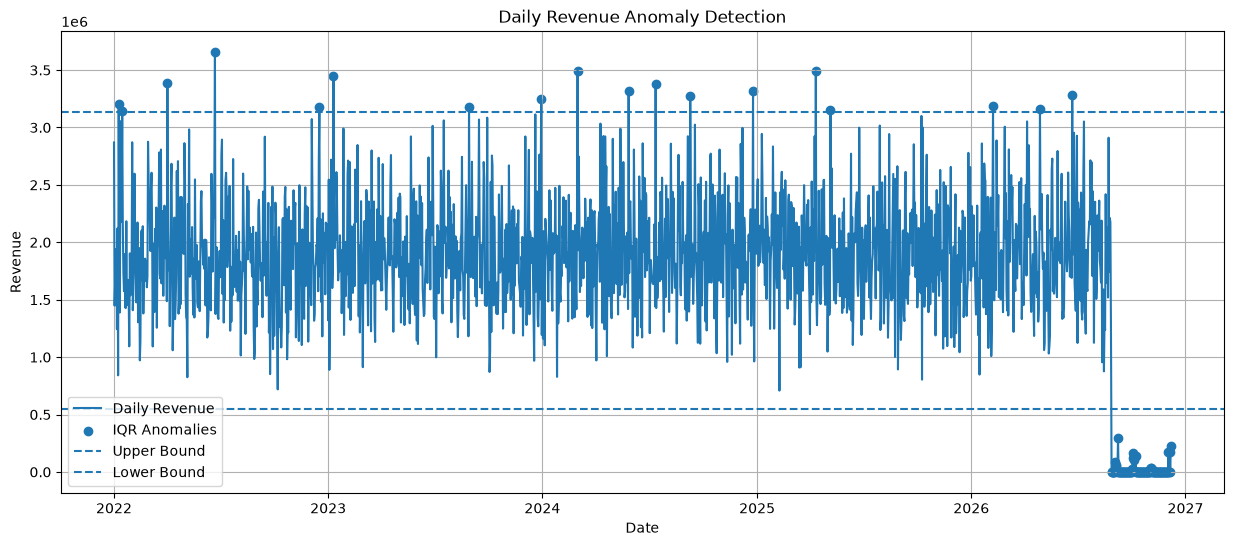

In [194]:
plt.figure(figsize=(15, 6))

plt.plot(
    anomaly_df.index,
    anomaly_df['revenue'],
    label='Daily Revenue'
)

plt.scatter(
    anomaly_df.index[anomaly_df['is_anomaly']],
    anomaly_df.loc[anomaly_df['is_anomaly'], 'revenue'],
    label='IQR Anomalies'
)

plt.axhline(
    upper_bound,
    linestyle='--',
    label='Upper Bound'
)

plt.axhline(
    lower_bound,
    linestyle='--',
    label='Lower Bound'
)

plt.title('Daily Revenue Anomaly Detection')
plt.xlabel('Date')
plt.ylabel('Revenue')
plt.legend()
plt.grid(True)

plt.show()